In [ ]:
# =============================================================================
# Статистика для паспорта данных arXiv (читает parquet по частям, экономит память)
# Запуск в ноутбуке:  exec(open('passport_stats.py').read())
# Во время расчёта печатается ход работы, в конце - таблицы и файл passport_stats.json
# =============================================================================
import os, json
from pathlib import Path

import numpy as np
import polars as pl

ROOT = Path(os.environ.get("ARXIV_ROOT", "data/optimized_v1"))


def parts(sub):
    return sorted((ROOT / sub).glob("part_*.parquet"))


def names(path):
    return pl.scan_parquet(path).collect_schema().names()


def size_mb(sub):
    return sum(p.stat().st_size for p in parts(sub)) / 1e6


def count_rows(sub):
    return sum(pl.scan_parquet(p).select(pl.len()).collect().item() for p in parts(sub))


def stat(a):
    a = np.asarray(a)
    return dict(mean=float(a.mean()), median=float(np.median(a)),
                min=float(a.min()), max=float(a.max())) if a.size else {}


result = {"rows": {}, "size_mb": {}, "text": {}, "numbers": {}, "dates": {}}

# ---------- 1) объём ----------
for sub in ["meta", "texts", "authors", "versions"]:
    result["rows"][sub] = count_rows(sub)
    result["size_mb"][sub] = round(size_mb(sub), 1)
    print(f"⏳ Считаю объём: {sub}")

# ---------- 2) текстовые поля: заполненность, знаки, слова ----------
TEXT = [  # (папка, возможные имена столбца, название для паспорта)
    ("texts", ["title"], "Название"),
    ("texts", ["abstract"], "Аннотация"),
    ("meta", ["comments"], "Комментарий автора"),
    ("meta", ["journal-ref", "journal_ref"], "Ссылка на журнал"),
    ("meta", ["doi"], "DOI"),
    ("meta", ["report-no", "report_no"], "Номер отчёта"),
    ("meta", ["submitter"], "Кто подал статью"),
]

for sub, cands, label in TEXT:
    total = filled = 0
    chars, words = [], []
    for p in parts(sub):
        col = next((c for c in cands if c in names(p)), None)
        if col is None:
            continue
        s = pl.read_parquet(p, columns=[col])[col].cast(pl.String)
        total += len(s)
        s = s.filter(s.is_not_null())
        s = s.filter(s.str.strip_chars().str.len_chars() > 0)
        filled += len(s)
        chars.append(s.str.len_chars().to_numpy())
        words.append(s.str.count_matches(r"\S+").to_numpy())
        del s
    if not total:
        continue
    ch = np.concatenate(chars) if chars else np.array([])
    wd = np.concatenate(words) if words else np.array([])
    r = dict(total=total, filled=filled, filled_pct=100 * filled / total,
             chars=stat(ch), words=stat(wd))
    result["text"][label] = r
    print(f"⏳ Текстовое поле готово: {label}")

# ---------- 3) числовые поля ----------
for col, label in [("n_authors", "Число авторов"), ("n_versions", "Число версий")]:
    vals = []
    for p in parts("meta"):
        if col in names(p):
            vals.append(pl.read_parquet(p, columns=[col])[col].drop_nulls().to_numpy())
    if vals:
        r = stat(np.concatenate(vals))
        result["numbers"][label] = r
        print(f"⏳ Числовое поле готово: {label}")

# ---------- 4) категории ----------
cnt, cats = [], set()
for p in parts("meta"):
    if "categories" not in names(p):
        continue
    s = pl.read_parquet(p, columns=["categories"])["categories"]
    if s.dtype == pl.List:
        lst = s.cast(pl.List(pl.String))
    else:
        lst = (s.cast(pl.String).fill_null("")
                .str.replace_all(r"[{},]", " ").str.strip_chars().str.split(" "))
    cnt.append(lst.list.eval(pl.element().filter(pl.element() != "")).list.len().fill_null(0).to_numpy())
    cats.update(lst.explode().drop_nulls().unique().to_list())
cats.discard("")
if cnt:
    r = stat(np.concatenate(cnt))
    r["distinct"] = len(cats)
    result["numbers"]["Категорий на статью"] = r
    print("⏳ Рубрики готовы")

# ---------- 5) даты ----------
for sub, col, label in [("meta", "update_date", "Дата обновления"), ("versions", "created", "Дата создания версии")]:
    lo = hi = None
    for p in parts(sub):
        if col not in names(p):
            continue
        s = pl.read_parquet(p, columns=[col])[col].drop_nulls()
        if len(s):
            a, b = s.min(), s.max()
            lo = a if lo is None or a < lo else lo
            hi = b if hi is None or b > hi else hi
    result["dates"][label] = [str(lo), str(hi)]

Path("passport_stats.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")

# =============================================================================
# Красивый вывод для ноутбука
# =============================================================================
# --- РИСОВАНИЕ ---
import html
from IPython.display import HTML, Markdown, clear_output, display

TH = "text-align:{a};padding:6px 12px;background:rgba(128,128,128,.18);border-bottom:2px solid rgba(128,128,128,.4);white-space:nowrap;"
TD = "text-align:{a};padding:6px 12px;border-bottom:1px solid rgba(128,128,128,.25);vertical-align:middle;"


def num(x, digits=0):
    """1234567.8 -> '1 234 567,8' (пробел между тысячами, запятая в дробях)."""
    return f"{x:,.{digits}f}".replace(",", "\u00a0").replace(".", ",")


def table(head, body, align=None):
    """head - заголовки, body - строки (ячейки уже в HTML), align - 'l'/'r' на столбец."""
    align = align or ["l"] * len(head)
    side = {"l": "left", "r": "right"}
    out = ['<table style="border-collapse:collapse;font-size:13px;"><thead><tr>']
    out += [f'<th style="{TH.format(a=side[a])}">{html.escape(h)}</th>' for h, a in zip(head, align)]
    out.append("</tr></thead><tbody>")
    for row in body:
        out.append("<tr>" + "".join(f'<td style="{TD.format(a=side[a])}">{c}</td>' for c, a in zip(row, align)) + "</tr>")
    out.append("</tbody></table>")
    return "".join(out)


def bar(pct):
    """Полоска заполненности + число."""
    return (f'<div style="display:flex;align-items:center;gap:8px;justify-content:flex-end;">'
            f'<div style="width:90px;height:8px;background:rgba(128,128,128,.25);border-radius:4px;overflow:hidden;">'
            f'<div style="width:{pct:.1f}%;height:100%;background:#3b82f6;"></div></div>'
            f'<span style="min-width:52px;text-align:right;">{num(pct, 1)}&nbsp;%</span></div>')


clear_output(wait=True)

# 1) объём
WHAT = {"meta": "Сведения о статьях (рубрики, даты, DOI, кто подал…)",
        "texts": "Названия и аннотации",
        "authors": "Авторы (одна строка на автора)",
        "versions": "Версии статей (одна строка на версию)"}
display(Markdown("## 1. Объём данных"))
display(HTML(table(
    ["Часть набора", "Что хранит", "Строк", "Размер файлов, МБ"],
    [[f"<b>{k}</b>", WHAT[k], num(result["rows"][k]), num(result["size_mb"][k], 1)] for k in result["rows"]],
    ["l", "l", "r", "r"])))
display(Markdown(f"Всего файлов-частей в каждой папке: {len(parts('meta'))}. "
                 f"Общий размер: **{num(sum(result['size_mb'].values()), 1)} МБ**."))

# 2) текстовые поля
display(Markdown("## 2. Текстовые поля\nЗнаки считаются вместе с пробелами; слово - любая группа знаков между пробелами."))
body = []
for label, r in result["text"].items():
    c, w = r["chars"], r["words"]
    body.append([f"<b>{html.escape(label)}</b>", bar(r["filled_pct"]), num(r["filled"]),
                 num(c.get("min", 0)), num(c.get("mean", 0), 1), num(c.get("median", 0)), num(c.get("max", 0)),
                 num(w.get("min", 0)), num(w.get("mean", 0), 1), num(w.get("median", 0)), num(w.get("max", 0))])
display(HTML(table(
    ["Поле", "Заполнено", "Статей с значением",
     "Знаков: наименьшее", "среднее", "медиана", "наибольшее",
     "Слов: наименьшее", "среднее", "медиана", "наибольшее"],
    body, ["l", "r", "r"] + ["r"] * 8)))
display(Markdown("Наименьшее считается только среди заполненных значений: пустые поля в него не входят."))

# 3) числовые поля
display(Markdown("## 3. Числовые поля"))
UNIT = {"Число авторов": "человек на статью", "Число версий": "версий на статью",
        "Категорий на статью": "рубрик на статью"}
body = []
for label, r in result["numbers"].items():
    body.append([f"<b>{html.escape(label)}</b>", UNIT.get(label, ""),
                 num(r["mean"], 2), num(r["median"], 1), num(r["min"]), num(r["max"])])
display(HTML(table(["Показатель", "Единица", "Среднее", "Медиана", "Наименьшее", "Наибольшее"],
                   body, ["l", "l", "r", "r", "r", "r"])))
if "Категорий на статью" in result["numbers"]:
    display(Markdown(f"Всего различных рубрик в наборе: **{num(result['numbers']['Категорий на статью']['distinct'])}**."))

# 4) даты
display(Markdown("## 4. Даты"))
display(HTML(table(
    ["Поле", "Самая ранняя", "Самая поздняя"],
    [[f"<b>{html.escape(k)}</b>", html.escape(str(v[0])[:10]), html.escape(str(v[1])[:10])]
     for k, v in result["dates"].items()],
    ["l", "r", "r"])))

display(Markdown("✅ Готово. Все числа сохранены в `passport_stats.json`."))

In [4]:
# =============================================================================
# Статистика для паспорта данных arXiv (читает parquet по частям, экономит память)
# Запуск в ноутбуке:  exec(open('passport_stats.py').read())
# Во время расчёта печатается ход работы, в конце - таблицы и файл passport_stats.json
# =============================================================================
import os, json
from pathlib import Path

import numpy as np
import polars as pl

ROOT = Path(os.environ.get("ARXIV_ROOT", "data/optimized_v1"))


def parts(sub):
    return sorted((ROOT / sub).glob("part_*.parquet"))


def names(path):
    return pl.scan_parquet(path).collect_schema().names()


def size_mb(sub):
    return sum(p.stat().st_size for p in parts(sub)) / 1e6


def count_rows(sub):
    return sum(pl.scan_parquet(p).select(pl.len()).collect().item() for p in parts(sub))


def stat(a):
    a = np.asarray(a)
    return dict(mean=float(a.mean()), median=float(np.median(a)),
                min=float(a.min()), max=float(a.max())) if a.size else {}


result = {"rows": {}, "size_mb": {}, "text": {}, "numbers": {}, "dates": {}}

# ---------- 1) объём ----------
for sub in ["meta", "texts", "authors", "versions"]:
    result["rows"][sub] = count_rows(sub)
    result["size_mb"][sub] = round(size_mb(sub), 1)
    print(f"⏳ Считаю объём: {sub}")

# ---------- 2) текстовые поля: заполненность, знаки, слова ----------
TEXT = [  # (папка, возможные имена столбца, название для паспорта)
    ("texts", ["title"], "Название"),
    ("texts", ["abstract"], "Аннотация"),
    ("meta", ["comments"], "Комментарий автора"),
    ("meta", ["journal-ref", "journal_ref"], "Ссылка на журнал"),
    ("meta", ["doi"], "DOI"),
    ("meta", ["report-no", "report_no"], "Номер отчёта"),
    ("meta", ["submitter"], "Кто подал статью"),
]

for sub, cands, label in TEXT:
    total = filled = 0
    chars, words = [], []
    for p in parts(sub):
        col = next((c for c in cands if c in names(p)), None)
        if col is None:
            continue
        s = pl.read_parquet(p, columns=[col])[col].cast(pl.String)
        total += len(s)
        s = s.filter(s.is_not_null())
        s = s.filter(s.str.strip_chars().str.len_chars() > 0)
        filled += len(s)
        chars.append(s.str.len_chars().to_numpy())
        words.append(s.str.count_matches(r"\S+").to_numpy())
        del s
    if not total:
        continue
    ch = np.concatenate(chars) if chars else np.array([])
    wd = np.concatenate(words) if words else np.array([])
    r = dict(total=total, filled=filled, filled_pct=100 * filled / total,
             chars=stat(ch), words=stat(wd))
    result["text"][label] = r
    print(f"⏳ Текстовое поле готово: {label}")

# ---------- 3) числовые поля ----------
for col, label in [("n_authors", "Число авторов"), ("n_versions", "Число версий")]:
    vals = []
    for p in parts("meta"):
        if col in names(p):
            vals.append(pl.read_parquet(p, columns=[col])[col].drop_nulls().to_numpy())
    if vals:
        r = stat(np.concatenate(vals))
        result["numbers"][label] = r
        print(f"⏳ Числовое поле готово: {label}")

# ---------- 4) категории ----------
cnt, cats = [], set()
for p in parts("meta"):
    if "categories" not in names(p):
        continue
    s = pl.read_parquet(p, columns=["categories"])["categories"]
    if s.dtype == pl.List:
        lst = s.cast(pl.List(pl.String))
    else:
        lst = (s.cast(pl.String).fill_null("")
                .str.replace_all(r"[{},]", " ").str.strip_chars().str.split(" "))
    cnt.append(lst.list.eval(pl.element().filter(pl.element() != "")).list.len().fill_null(0).to_numpy())
    cats.update(lst.explode().drop_nulls().unique().to_list())
cats.discard("")
if cnt:
    r = stat(np.concatenate(cnt))
    r["distinct"] = len(cats)
    result["numbers"]["Категорий на статью"] = r
    print("⏳ Рубрики готовы")

# ---------- 5) даты ----------
for sub, col, label in [("meta", "update_date", "Дата обновления"), ("versions", "created", "Дата создания версии")]:
    lo = hi = None
    for p in parts(sub):
        if col not in names(p):
            continue
        s = pl.read_parquet(p, columns=[col])[col].drop_nulls()
        if len(s):
            a, b = s.min(), s.max()
            lo = a if lo is None or a < lo else lo
            hi = b if hi is None or b > hi else hi
    result["dates"][label] = [str(lo), str(hi)]

Path("passport_stats.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")

# =============================================================================
# Красивый вывод для ноутбука
# =============================================================================
# --- РИСОВАНИЕ ---
import html
from IPython.display import HTML, Markdown, clear_output, display

TH = "text-align:{a};padding:6px 12px;background:rgba(128,128,128,.18);border-bottom:2px solid rgba(128,128,128,.4);white-space:nowrap;"
TD = "text-align:{a};padding:6px 12px;border-bottom:1px solid rgba(128,128,128,.25);vertical-align:middle;"


def num(x, digits=0):
    """1234567.8 -> '1 234 567,8' (пробел между тысячами, запятая в дробях)."""
    return f"{x:,.{digits}f}".replace(",", "\u00a0").replace(".", ",")


def table(head, body, align=None):
    """head - заголовки, body - строки (ячейки уже в HTML), align - 'l'/'r' на столбец."""
    align = align or ["l"] * len(head)
    side = {"l": "left", "r": "right"}
    out = ['<table style="border-collapse:collapse;font-size:13px;"><thead><tr>']
    out += [f'<th style="{TH.format(a=side[a])}">{html.escape(h)}</th>' for h, a in zip(head, align)]
    out.append("</tr></thead><tbody>")
    for row in body:
        out.append("<tr>" + "".join(f'<td style="{TD.format(a=side[a])}">{c}</td>' for c, a in zip(row, align)) + "</tr>")
    out.append("</tbody></table>")
    return "".join(out)


def bar(pct):
    """Полоска заполненности + число."""
    return (f'<div style="display:flex;align-items:center;gap:8px;justify-content:flex-end;">'
            f'<div style="width:90px;height:8px;background:rgba(128,128,128,.25);border-radius:4px;overflow:hidden;">'
            f'<div style="width:{pct:.1f}%;height:100%;background:#3b82f6;"></div></div>'
            f'<span style="min-width:52px;text-align:right;">{num(pct, 1)}&nbsp;%</span></div>')


clear_output(wait=True)

# 1) объём
WHAT = {"meta": "Сведения о статьях (рубрики, даты, DOI, кто подал…)",
        "texts": "Названия и аннотации",
        "authors": "Авторы (одна строка на автора)",
        "versions": "Версии статей (одна строка на версию)"}
display(Markdown("## 1. Объём данных"))
display(HTML(table(
    ["Часть набора", "Что хранит", "Строк", "Размер файлов, МБ"],
    [[f"<b>{k}</b>", WHAT[k], num(result["rows"][k]), num(result["size_mb"][k], 1)] for k in result["rows"]],
    ["l", "l", "r", "r"])))
display(Markdown(f"Всего файлов-частей в каждой папке: {len(parts('meta'))}. "
                 f"Общий размер: **{num(sum(result['size_mb'].values()), 1)} МБ**."))

# 2) текстовые поля
display(Markdown("## 2. Текстовые поля\nЗнаки считаются вместе с пробелами; слово - любая группа знаков между пробелами."))
body = []
for label, r in result["text"].items():
    c, w = r["chars"], r["words"]
    body.append([f"<b>{html.escape(label)}</b>", bar(r["filled_pct"]), num(r["filled"]),
                 num(c.get("min", 0)), num(c.get("mean", 0), 1), num(c.get("median", 0)), num(c.get("max", 0)),
                 num(w.get("min", 0)), num(w.get("mean", 0), 1), num(w.get("median", 0)), num(w.get("max", 0))])
display(HTML(table(
    ["Поле", "Заполнено", "Статей с значением",
     "Знаков: наименьшее", "среднее", "медиана", "наибольшее",
     "Слов: наименьшее", "среднее", "медиана", "наибольшее"],
    body, ["l", "r", "r"] + ["r"] * 8)))
display(Markdown("Наименьшее считается только среди заполненных значений: пустые поля в него не входят."))

# 3) числовые поля
display(Markdown("## 3. Числовые поля"))
UNIT = {"Число авторов": "человек на статью", "Число версий": "версий на статью",
        "Категорий на статью": "рубрик на статью"}
body = []
for label, r in result["numbers"].items():
    body.append([f"<b>{html.escape(label)}</b>", UNIT.get(label, ""),
                 num(r["mean"], 2), num(r["median"], 1), num(r["min"]), num(r["max"])])
display(HTML(table(["Показатель", "Единица", "Среднее", "Медиана", "Наименьшее", "Наибольшее"],
                   body, ["l", "l", "r", "r", "r", "r"])))
if "Категорий на статью" in result["numbers"]:
    display(Markdown(f"Всего различных рубрик в наборе: **{num(result['numbers']['Категорий на статью']['distinct'])}**."))

# 4) даты
display(Markdown("## 4. Даты"))
display(HTML(table(
    ["Поле", "Самая ранняя", "Самая поздняя"],
    [[f"<b>{html.escape(k)}</b>", html.escape(str(v[0])[:10]), html.escape(str(v[1])[:10])]
     for k, v in result["dates"].items()],
    ["l", "r", "r"])))

display(Markdown("✅ Готово. Все числа сохранены в `passport_stats.json`."))

## 1. Объём данных

Часть набора,Что хранит,Строк,"Размер файлов, МБ"
meta,"Сведения о статьях (рубрики, даты, DOI, кто подал…)",3 148 882,"97,8"
texts,Названия и аннотации,3 148 882,"1 085,4"
authors,Авторы (одна строка на автора),14 989 782,"94,4"
versions,Версии статей (одна строка на версию),5 030 734,"38,0"


Всего файлов-частей в каждой папке: 16. Общий размер: **1 315,6 МБ**.

## 2. Текстовые поля
Знаки считаются вместе с пробелами; слово - любая группа знаков между пробелами.

Поле,Заполнено,Статей с значением,Знаков: наименьшее,среднее,медиана,наибольшее,Слов: наименьшее,среднее,медиана,наибольшее
Название,"100,0 %",3 148 882,1,"76,0",75,382,1,"9,9",9,61
Аннотация,"100,0 %",3 148 882,3,"1 009,5",993,6 091,1,"146,4",144,925
Комментарий автора,"72,0 %",2 267 865,1,"59,6",40,1 150,1,"9,3",7,187
Ссылка на журнал,"30,5 %",961 830,1,"41,3",33,557,1,"6,2",6,71
DOI,"42,2 %",1 329 740,7,"25,1",26,153,1,"1,0",1,9
Номер отчёта,"6,1 %",192 824,1,"19,7",15,509,1,"1,8",1,65
Кто подал статью,"99,5 %",3 133 697,1,"14,2",14,64,1,"2,2",2,14


...

Показатель,Единица,Среднее,Медиана,Наименьшее,Наибольшее
Число авторов,человек на статью,"4,20","3,0",0,255
Число версий,версий на статью,"1,60","1,0",1,187
Категорий на статью,рубрик на статью,"1,74","1,0",1,13


Всего различных рубрик в наборе: **176**.

## 4. Даты

Поле,Самая ранняя,Самая поздняя
Дата обновления,2007-05-23,2026-08-28
Дата создания версии,1986-04-25,2026-08-27


✅ Готово. Все числа сохранены в `passport_stats.json`.

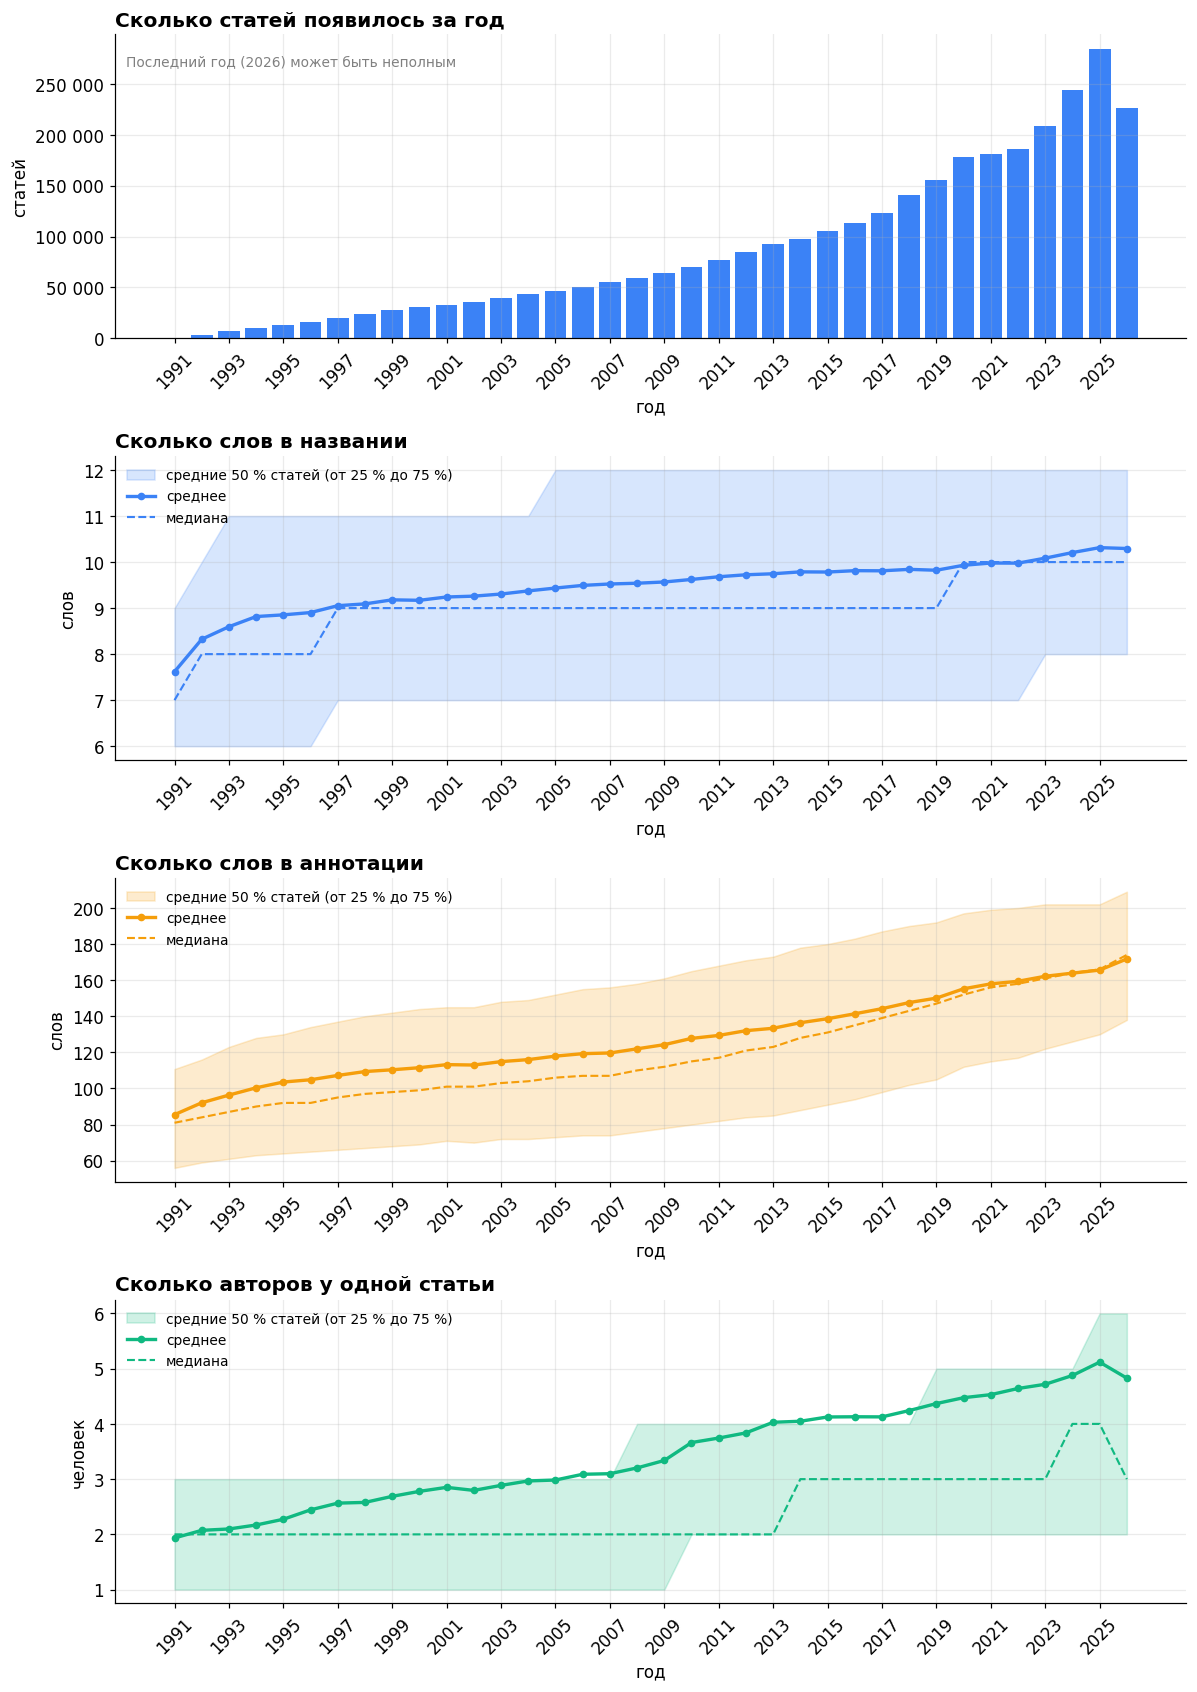

- Всего статей: **3 148 882**; больше всего — в 2025 г. (**284 486**)
- Слов в названии: в 1991 г. в среднем **7.6**, в 2026 г. — **10.3**
- Слов в аннотации: в 1991 г. в среднем **85.5**, в 2026 г. — **171.8**
- Авторов на статью: в 1991 г. в среднем **1.9**, в 2026 г. — **4.8**

In [6]:
# =============================================================================
# Тренды по годам: число статей, длина названий и аннотаций (в словах), число авторов
# Запуск в отдельной ячейке ноутбука:  exec(open('plot_trends.py').read())
# =============================================================================
import os
from pathlib import Path

import numpy as np
import polars as pl

ROOT = Path(os.environ.get("ARXIV_ROOT", "data/optimized_v1"))


def parts(sub):
    return sorted((ROOT / sub).glob("part_*.parquet"))


# ---------- 1) читаем по частям: год статьи и число слов ----------
# Год берём из номера статьи: id_ym = ГГММ (например 704 -> 2007 г., 9901 -> 1999 г.); arXiv начался в 1991 году.
years, tw, aw = [], [], []
for i, p in enumerate(parts("texts"), 1):
    d = pl.read_parquet(p, columns=["id_ym", "title", "abstract"])
    yy = (d["id_ym"].cast(pl.Int64) // 100).to_numpy()
    years.append(np.where(yy >= 91, 1900 + yy, 2000 + yy).astype(np.int16))
    tw.append(d["title"].cast(pl.String).fill_null("").str.count_matches(r"\S+").to_numpy().astype(np.int32))
    aw.append(d["abstract"].cast(pl.String).fill_null("").str.count_matches(r"\S+").to_numpy().astype(np.int32))
    del d
    print(f"⏳ Прочитано частей: {i}", end="\r")

years, tw, aw = map(np.concatenate, (years, tw, aw))
all_years = np.arange(years.min(), years.max() + 1)

# число авторов лежит в сведениях о статьях (meta)
years_m, na = [], []
for i, p in enumerate(parts("meta"), 1):
    d = pl.read_parquet(p, columns=["id_ym", "n_authors"])
    yy = (d["id_ym"].cast(pl.Int64) // 100).to_numpy()
    years_m.append(np.where(yy >= 91, 1900 + yy, 2000 + yy).astype(np.int16))
    na.append(d["n_authors"].fill_null(0).to_numpy().astype(np.int32))
    del d
    print(f"⏳ Прочитано частей со сведениями: {i}", end="\r")
years_m, na = np.concatenate(years_m), np.concatenate(na)


def by_year(values, yrs=None):
    """По каждому году: среднее, медиана, 25-й и 75-й процентили."""
    yrs = years if yrs is None else yrs
    rows = []
    for y in all_years:
        v = values[yrs == y]
        rows.append((v.mean(), *np.percentile(v, [50, 25, 75])) if v.size else (np.nan,) * 4)
    return np.array(rows)


count = np.array([(years == y).sum() for y in all_years])
title_s, abs_s, auth_s = by_year(tw), by_year(aw), by_year(na, years_m)

# ---------- 2) рисуем ----------
import io
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, clear_output, display

clear_output(wait=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})
BLUE, ORANGE = "#3b82f6", "#f59e0b"

fig, axes = plt.subplots(4, 1, figsize=(11, 15.5), sharex=True)

ax = axes[0]
ax.bar(all_years, count, color=BLUE)
ax.set_title("Сколько статей появилось за год", loc="left", fontweight="bold")
ax.set_ylabel("статей")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
ax.text(0.01, 0.93, f"Последний год ({all_years[-1]}) может быть неполным", transform=ax.transAxes, fontsize=9, color="gray", va="top")

for ax, s, name, color in [(axes[1], title_s, "названии", BLUE), (axes[2], abs_s, "аннотации", ORANGE),
                                    (axes[3], auth_s, "списке авторов", "#10b981")]:
    ax.fill_between(all_years, s[:, 2], s[:, 3], color=color, alpha=.2, label="средние 50 % статей (от 25 % до 75 %)")
    ax.plot(all_years, s[:, 0], color=color, lw=2.2, marker="o", ms=4, label="среднее")
    ax.plot(all_years, s[:, 1], color=color, lw=1.4, ls="--", label="медиана")
    ax.set_title(f"Сколько слов в {name}" if "авторов" not in name else "Сколько авторов у одной статьи",
                 loc="left", fontweight="bold")
    ax.set_ylabel("слов" if "авторов" not in name else "человек")
    ax.legend(frameon=False, loc="upper left", fontsize=9)

for ax in axes:  # подписи годов под каждым графиком
    ax.set_xlabel("год")
    ax.set_xticks(all_years[::2])
    ax.tick_params(axis="x", labelbottom=True)
    plt.setp(ax.get_xticklabels(), rotation=45)
fig.tight_layout()
# Картинку выводим сами (в памяти), чтобы она показалась при любом режиме графиков в ноутбуке
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
plt.close(fig)
display(Image(data=buf.getvalue()))

# ---------- 3) короткий вывод словами ----------
def change(s, label):
    a, b = np.nanargmax(~np.isnan(s[:, 0])), len(s) - 1
    return f"{label}: в {all_years[a]} г. в среднем **{s[a, 0]:.1f}**, в {all_years[b]} г. — **{s[b, 0]:.1f}**"

peak = all_years[count.argmax()]
display(Markdown(
    f"- Всего статей: **{count.sum():,}**; больше всего — в {peak} г. (**{count.max():,}**)\n".replace(",", " ")
    + f"- {change(title_s, 'Слов в названии')}\n- {change(abs_s, 'Слов в аннотации')}\n- {change(auth_s, 'Авторов на статью')}"))

## Сводка

| Критерий | Статей | Доля от всех |
|---|---:|---:|
| Статьи, где 0 авторов | 19 | 0,00 % |
| Статьи с названием не длиннее 2 слов | 13 173 | 0,42 % |
| Статьи с аннотацией не длиннее 10 слов | 2 121 | 0,07 % |

Всего статей в наборе: **3 148 882**. Пороги можно менять в начале скрипта.

## Графики по годам

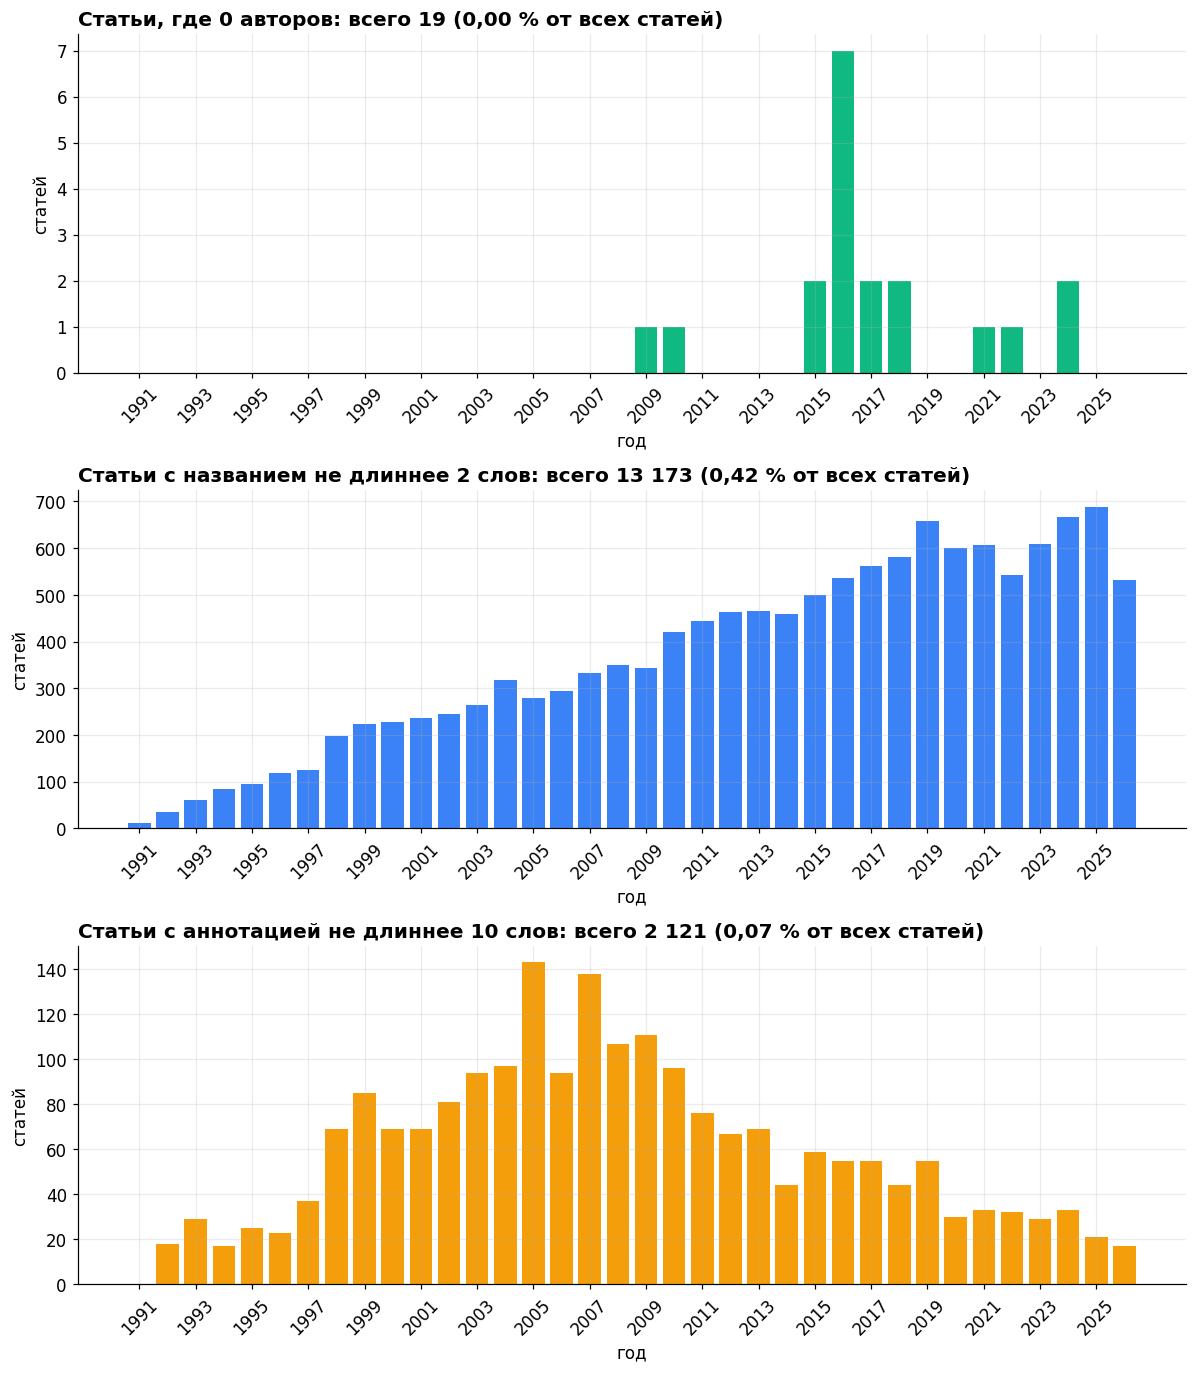

## Примеры: название не длиннее 2 слов
Сначала статьи с DOI, внутри — самые короткие названия.

№,Номер,Название,Аннотация,Слов / знаков в названии,Слов / знаков в аннотации,Авторов,Рубрики,Ссылки
1,new/1708770,QCD,"In these lecture notes I describe the theory of QCD and its application, through perturbation theory, at particle colliders.",1 / 3,19 / 127,1,hep-ph,arXiv · DOI
2,new/22115532,316,"A room, a teacher and many friends.",1 / 3,7 / 35,1,physics.hist-ph gr-qc hep-th math.HO,arXiv · DOI
3,new/21052313,iCub,In this chapter we describe the history and evolution of the iCub humanoid platform. We start by describing the first version as it was designed during the Robo…,1 / 4,103 / 611,5,cs.RO,arXiv · DOI
4,astro-ph/0103272,GEST,Galactic Exoplanet Survey Telescope (GEST) was proposed for a discovery mission to search for microlensing terrestrial planets toward the Galactic bulge and als…,1 / 4,175 / 1137,1,astro-ph,arXiv · DOI
5,new/15123658,Gaia,"A review of the Gaia mission and its science performance after one year of operations will be presented, and the contribution to reconstructing the history of t…",1 / 4,32 / 193,3,astro-ph.GA astro-ph.IM,arXiv · DOI
6,new/0812474,Lh_c,"The production cross-section of h_c, the 1P_1 charmonium state, can be predicted in Non-Relativistic QCD (NRQCD) using heavy-quark symmetry. We show that at the…",1 / 4,68 / 408,1,hep-ph,arXiv · DOI
7,hep-ex/0002045,Selex,A summary of the path which lead to a high energy physics group at Instituto de Fisica de la Universidad Autonoma de San Luis Potosi is presented. This group is…,1 / 5,46 / 246,1,hep-ex,arXiv · DOI
8,hep-th/9707250,M&m's,We consider M theory 5-branes with compact transverse dimensions. In certain limits the theory on the 5-brane decouples and defines ``little string theories'' i…,1 / 5,86 / 573,3,hep-th,arXiv · DOI
9,new/210414656,HOSS!,The Hall-D Online Skim System (HOSS) was developed to simultaneously solve two issues for the high intensity GlueX experiment. One was to parallelize the writin…,1 / 5,83 / 522,1,physics.ins-det hep-ex,arXiv · DOI
10,new/07114657,Icons,"Categorical orthodoxy has it that collections of ordinary mathematical structures such as groups, rings, or spaces, form categories (such as the category of gro…",1 / 5,147 / 1024,1,math.CT,arXiv · DOI


## Примеры: аннотация не длиннее 10 слов
Сначала статьи с DOI, внутри — самые короткие аннотации.

№,Номер,Название,Аннотация,Слов / знаков в названии,Слов / знаков в аннотации,Авторов,Рубрики,Ссылки
1,new/16091476,Can decay be ascribed to classical noise?,No.,7 / 41,1 / 6,6,quant-ph math-ph math.MP,arXiv · DOI
2,new/180711336,Are theoretical results 'Results'?,Yes.,4 / 34,1 / 7,1,q-bio.OT cond-mat.soft physics.bio-ph,arXiv · DOI
3,new/1602251,Do we have privacy in the digital world?,Not really.,8 / 40,2 / 14,1,cs.CR cs.HC cs.IR,arXiv · DOI
4,new/11102832,Can apparent superluminal neutrino speeds be explained as a quantum weak measurement?,Probably not.,12 / 87,2 / 16,4,hep-ph hep-ex quant-ph,arXiv · DOI
5,new/17045045,Sub-100 nm 3-D fluorescence lifetime imaging using time correlated single photon counting detection and multifocal multiphoton excitation,Abstract removed.,17 / 139,2 / 20,1,physics.optics cond-mat.mes-hall physics.ins-det,arXiv · DOI
6,new/07043345,(Erratum) An f(R) gravitation for galactic environments,Without abstract.,7 / 55,2 / 20,2,astro-ph,arXiv · DOI
7,astro-ph/0511670,Island Universes,Conference Summary,2 / 16,2 / 21,1,astro-ph,arXiv · DOI
8,hep-th/9905181,Superconformal Algebras on the Boundary of AdS_3,See hep-th/0002188,7 / 48,2 / 21,1,hep-th math.QA,arXiv · DOI
9,hep-th/9903184,Path integral evaluation of Dbrane amplitudes,See hep-th/9907179.,6 / 45,2 / 22,1,hep-th,arXiv · DOI
10,new/12115927,Optimal quantum communication using multiparticle partially entangled states,Administratively withdrawn.,8 / 78,2 / 30,4,quant-ph,arXiv · DOI


## Примеры: 0 авторов
Сначала статьи с DOI, внутри — самые ранние номера.

№,Номер,Название,Аннотация,Слов / знаков в названии,Слов / знаков в аннотации,Авторов,Рубрики,Ссылки
1,new/10114079,Search for Gravitational Wave Bursts from Six Magnetars,Soft gamma repeaters (SGRs) and anomalous X-ray pulsars (AXPs) are thought to be magnetars: neutron stars powered by extreme magnetic fields. These rare objects…,8 / 55,247 / 1548,0,astro-ph.HE gr-qc,arXiv · DOI
2,new/15067834,Measurement of higher cumulants of net-charge multiplicity distributions in Au$+$Au collisions at $\sqrt{s_{_{NN}}}=7.7-200$ GeV,"We report the measurement of cumulants ($C_n, n=1\ldots4$) of the net-charge distributions measured within pseudorapidity ($|\eta|<0.35$) in Au$+$Au collisions …",14 / 130,149 / 1092,0,nucl-ex,arXiv · DOI
3,new/15096337,$\phi$ meson production in the forward/backward rapidity region in Cu$+$Au collisions at $\sqrt{s_{NN}}=200$ GeV,The PHENIX experiment at the Relativistic Heavy Ion Collider (RHIC) has measured $\phi$ meson production and its nuclear modification in asymmetric Cu$+$Au heav…,14 / 114,124 / 914,0,nucl-ex,arXiv · DOI
4,new/16081289,Amplitude analysis of $B^{-} \to D^{+} \pi^{-} \pi^{-}$ decays,The Dalitz plot analysis technique is used to study the resonant substructures of $B^{-} \to D^{+} \pi^{-} \pi^{-}$ decays in a data sample corresponding to 3.0…,9 / 62,156 / 1159,0,hep-ex,arXiv · DOI
5,new/16081484,"Measurement of forward $W\to e\nu$ production in $pp$ collisions at $\sqrt{s}=8\,$TeV","A measurement of the cross-section for $W \to e\nu$ production in $pp$ collisions is presented using data corresponding to an integrated luminosity of $2\,$fb$^…",11 / 87,193 / 1520,0,hep-ex,arXiv · DOI
6,new/1609600,The supernova remnant W49B as seen with H.E.S.S. and Fermi-LAT,"The supernova remnant (SNR) W49B originated from a core-collapse supernova that occurred between one and four thousand years ago, and subsequently evolved into …",10 / 62,177 / 1208,0,astro-ph.HE,arXiv · DOI
7,new/16098671,H.E.S.S. observations of RX J1713.7-3946 with improved angular and spectral resolution; evidence for gamma-ray emission extending beyond the X-ray emitting shell,"Supernova remnants exhibit shock fronts (shells) that can accelerate charged particles up to very high energies. In the past decade, measurements of a handful o…",21 / 165,213 / 1496,0,astro-ph.HE,arXiv · DOI
8,new/16109476,Measurement of $CP$ asymmetry in $D^0\rightarrow K^-K^+$ decays,"A measurement of the time-integrated $CP$ asymmetry in the Cabibbo-suppressed decay $D^0\rightarrow K^-K^+$ is performed using pp collision data, corresponding …",8 / 63,149 / 1221,0,hep-ex,arXiv · DOI
9,new/16127451,"Measurement of the $J/\psi$ pair production cross-section in $pp$ collisions at $\sqrt{s} = 13 \,{\mathrm{TeV}}$",The production cross-section of $J/\psi$ pairs is measured using a data sample of $pp$ collisions collected by the LHCb experiment at a centre-of-mass energy of…,15 / 114,103 / 731,0,hep-ex,arXiv · DOI
10,new/16128110,Search for the $B^{0}_{s} \to \eta^{\prime}\phi$ decay,A search for the charmless $B^{0}_{s} \to \eta^{\prime}\phi$ decay is performed using $pp$ collision data collected by the LHCb experiment at centre-of-mass ene…,7 / 54,64 / 440,0,hep-ex,arXiv · DOI


In [8]:
# =============================================================================
# Аномалии: статьи без авторов, с очень короткими названиями и аннотациями
# Графики по годам + примеры статей со ссылками (arXiv и DOI) для проверки на сайте
# Запуск в отдельной ячейке ноутбука:  exec(open('check_small.py').read())
# =============================================================================
import os
from pathlib import Path

import numpy as np
import polars as pl

ROOT = Path(os.environ.get("ARXIV_ROOT", "data/optimized_v1"))
KEYS = ["id_prefix", "id_ym", "id_num"]

# ---- пороги: меняйте под себя ----
TITLE_MAX_WORDS = 2      # название считается «аномально коротким», если в нём не больше стольких слов
ABSTRACT_MAX_WORDS = 10  # то же для аннотации
N_EXAMPLES = 15          # сколько примеров показать в каждой группе


def parts(sub):
    return sorted((ROOT / sub).glob("part_*.parquet"))


def names(path):
    return pl.scan_parquet(path).collect_schema().names()


def read(path, columns):
    """Читает существующие столбцы и приводит ключи к одним типам."""
    have = set(names(path))
    d = pl.read_parquet(path, columns=[c for c in columns if c in have]).with_columns(
        pl.col("id_prefix").cast(pl.String), pl.col("id_ym").cast(pl.Int64), pl.col("id_num").cast(pl.Int64))
    if "categories" in d.columns:  # в разных файлах рубрики бывают списком или строкой
        c = pl.col("categories")
        d = d.with_columns(c.cast(pl.List(pl.String)).list.join(" ") if isinstance(d.schema["categories"], pl.List)
                           else c.cast(pl.String))
    if "update_date" in d.columns:
        d = d.with_columns(pl.col("update_date").cast(pl.String))
    return d


def year_expr():
    """Год из номера статьи: ГГММ -> 0704 = 2007 г., 9901 = 1999 г. (arXiv начался в 1991 году)."""
    yy = pl.col("id_ym") // 100
    return pl.when(yy >= 91).then(1900 + yy).otherwise(2000 + yy).alias("year")


def arxiv_id(prefix, ym, num):
    if prefix:
        return f"{prefix}/{int(ym):04d}{int(num):03d}"
    return f"{int(ym):04d}.{int(num):0{4 if int(ym) < 1501 else 5}d}"


def size_cols(prefix=""):
    t, a = pl.col("title").cast(pl.String).fill_null(""), pl.col("abstract").cast(pl.String).fill_null("")
    return [t.str.count_matches(r"\S+").alias("tw"), t.str.len_chars().alias("tc"),
            a.str.count_matches(r"\S+").alias("aw"), a.str.len_chars().alias("ac")]


# ---------- 1) названия и аннотации: считаем по частям ----------
yr_title, yr_abs, total_by_year, cand = [], [], [], []
for i, p in enumerate(parts("texts"), 1):
    d = read(p, KEYS + ["title", "abstract"]).with_columns(year_expr(), *size_cols())
    total_by_year.append(d.group_by("year").len())
    yr_title.append(d.filter(pl.col("tw") <= TITLE_MAX_WORDS)["year"].to_numpy())
    yr_abs.append(d.filter(pl.col("aw") <= ABSTRACT_MAX_WORDS)["year"].to_numpy())
    cand.append(d.filter((pl.col("tw") <= TITLE_MAX_WORDS) | (pl.col("aw") <= ABSTRACT_MAX_WORDS)))
    del d
    print(f"⏳ Названия и аннотации, частей: {i}", end="\r")
yr_title, yr_abs = np.concatenate(yr_title), np.concatenate(yr_abs)
cand = pl.concat(cand)
total_by_year = pl.concat(total_by_year).group_by("year").agg(pl.col("len").sum())
total_articles = int(total_by_year["len"].sum())

# ---------- 2) авторы: статьи с 0 авторов ----------
yr_zero, zero_rows = [], []
for i, p in enumerate(parts("meta"), 1):
    d = read(p, KEYS + ["n_authors", "doi", "categories", "update_date", "submitter"])
    z = d.filter(pl.col("n_authors") == 0).with_columns(year_expr())
    yr_zero.append(z["year"].to_numpy())
    zero_rows.append(z)
    print(f"⏳ Авторы, частей: {i}", end="\r")
yr_zero = np.concatenate(yr_zero)
zero_all = pl.concat(zero_rows, how="diagonal_relaxed")

# ---------- 3) подтягиваем DOI и прочее к коротким названиям/аннотациям ----------
info_cols = ["n_authors", "doi", "categories", "update_date", "submitter"]
info = pl.concat([read(p, KEYS + info_cols).join(cand.select(KEYS), on=KEYS, how="semi") for p in parts("meta")],
                 how="diagonal_relaxed")
cand = cand.join(info, on=KEYS, how="left")


def has_doi():
    return pl.col("doi").is_not_null() & (pl.col("doi").cast(pl.String).str.strip_chars() != "")


def pick(df, sort_by):
    """Примеры: сначала те, у которых есть DOI (их проще проверить), внутри - самые короткие."""
    return df.sort([has_doi().not_(), *sort_by]).head(N_EXAMPLES)


ex_title = pick(cand.filter(pl.col("tw") <= TITLE_MAX_WORDS), ["tw", "tc"])
ex_abs = pick(cand.filter(pl.col("aw") <= ABSTRACT_MAX_WORDS), ["aw", "ac"])

# для статей без авторов нужны названия и аннотации: берём только отобранные примеры
ex_zero = pick(zero_all, ["id_ym"])
texts = pl.concat([read(p, KEYS + ["title", "abstract"]).join(ex_zero.select(KEYS), on=KEYS, how="semi")
                   for p in parts("texts")])
ex_zero = ex_zero.join(texts, on=KEYS, how="left").with_columns(*size_cols())


def to_rows(df):
    out = []
    for r in df.iter_rows(named=True):
        cats = r.get("categories")
        if isinstance(cats, list):
            cats = " ".join(cats)
        aid = arxiv_id(r["id_prefix"], r["id_ym"], r["id_num"])
        doi = (r.get("doi") or "").strip() if r.get("doi") else ""
        out.append(dict(id=aid, title=r.get("title") or "", abstract=r.get("abstract") or "",
                        tw=r["tw"], tc=r["tc"], aw=r["aw"], ac=r["ac"], n_authors=r.get("n_authors"),
                        cats=cats or "", doi=doi))
    return out


examples = {"title": to_rows(ex_title), "abs": to_rows(ex_abs), "zero": to_rows(ex_zero)}

# =============================================================================
# РИСОВАНИЕ
# =============================================================================
# --- РИСОВАНИЕ ---
import html
import io

import matplotlib.pyplot as plt
from IPython.display import HTML, Image, Markdown, clear_output, display

all_years = np.arange(min(yr_zero.min() if yr_zero.size else 9999, yr_title.min() if yr_title.size else 9999,
                          yr_abs.min() if yr_abs.size else 9999, int(total_by_year["year"].min())),
                      int(total_by_year["year"].max()) + 1)
by_year = lambda a: np.array([(a == y).sum() for y in all_years])
tot = dict(zip(total_by_year["year"].to_list(), total_by_year["len"].to_list()))
total_arr = np.array([tot.get(int(y), 0) for y in all_years])
series = [
    (by_year(yr_zero), "Статьи, где 0 авторов", "#10b981"),
    (by_year(yr_title), f"Статьи с названием не длиннее {TITLE_MAX_WORDS} слов", "#3b82f6"),
    (by_year(yr_abs), f"Статьи с аннотацией не длиннее {ABSTRACT_MAX_WORDS} слов", "#f59e0b"),
]


def num(x):
    return f"{int(x):,}".replace(",", " ")


def pct(x):
    return f"{100 * x / total_articles:.2f}".replace(".", ",") + "\u00a0%"


clear_output(wait=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})
fig, axes = plt.subplots(len(series), 1, figsize=(11, 4.2 * len(series)))
for ax, (cnt, title, color) in zip(axes, series):
    ax.bar(all_years, cnt, color=color)
    ax.set_title(f"{title}: всего {num(cnt.sum())} ({pct(cnt.sum())} от всех статей)",
                 loc="left", fontweight="bold")
    ax.set_ylabel("статей")
    ax.set_xlabel("год")
    ax.set_xticks(all_years[::2])
    plt.setp(ax.get_xticklabels(), rotation=45)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
fig.tight_layout()
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
plt.close(fig)

display(Markdown("## Сводка"))
display(Markdown(
    "| Критерий | Статей | Доля от всех |\n|---|---:|---:|\n"
    + "\n".join(f"| {t} | {num(c.sum())} | {pct(c.sum())} |" for c, t, _ in series)
    + f"\n\nВсего статей в наборе: **{num(total_articles)}**. Пороги можно менять в начале скрипта."))
display(Markdown("## Графики по годам"))
display(Image(data=buf.getvalue()))

TH = "text-align:left;padding:6px 10px;background:rgba(128,128,128,.18);border-bottom:2px solid rgba(128,128,128,.4);"
TD = "padding:6px 10px;border-bottom:1px solid rgba(128,128,128,.25);vertical-align:top;"
e = lambda x: html.escape(str(x if x is not None else ""))


def cut(s, n=160):
    s = " ".join(str(s).split())
    return s if len(s) <= n else s[:n] + "…"


def table(rows):
    head = ["№", "Номер", "Название", "Аннотация", "Слов / знаков в названии", "Слов / знаков в аннотации",
            "Авторов", "Рубрики", "Ссылки"]
    out = ['<table style="border-collapse:collapse;font-size:13px;width:100%;"><thead><tr>'
           + "".join(f'<th style="{TH}">{h}</th>' for h in head) + "</tr></thead><tbody>"]
    for n, r in enumerate(rows, 1):
        links = f'<a href="https://arxiv.org/abs/{e(r["id"])}" target="_blank">arXiv</a>'
        links += (f' · <a href="https://doi.org/{e(r["doi"])}" target="_blank">DOI</a>' if r["doi"]
                  else ' · <span style="opacity:.5">нет DOI</span>')
        cells = [n, f"<b>{e(r['id'])}</b>", e(r["title"]) or "<i>(пусто)</i>", e(cut(r["abstract"])) or "<i>(пусто)</i>",
                 f"{r['tw']} / {r['tc']}", f"{r['aw']} / {r['ac']}", e(r["n_authors"]), e(r["cats"]), links]
        out.append("<tr>" + "".join(f'<td style="{TD}">{c}</td>' for c in cells) + "</tr>")
    out.append("</tbody></table>")
    return "".join(out)


for key, head, note in [
    ("title", f"Примеры: название не длиннее {TITLE_MAX_WORDS} слов", "Сначала статьи с DOI, внутри — самые короткие названия."),
    ("abs", f"Примеры: аннотация не длиннее {ABSTRACT_MAX_WORDS} слов", "Сначала статьи с DOI, внутри — самые короткие аннотации."),
    ("zero", "Примеры: 0 авторов", "Сначала статьи с DOI, внутри — самые ранние номера."),
]:
    display(Markdown(f"## {head}\n{note}"))
    display(HTML(table(examples[key])))

In [10]:
# =============================================================================
# Очистка набора: убираем статьи-аномалии (0 авторов, очень короткие название или аннотация)
# Исходные файлы НЕ меняются: чистая копия записывается в новую папку.
# Запуск в ноутбуке:  exec(open('clean_dataset.py').read())
# Результат: папка data/optimized_v1_clean (те же 4 подпапки и те же имена частей)
#            + файл removed_records.csv со списком убранных статей и причиной
# =============================================================================
import os
from pathlib import Path

import polars as pl

ROOT = Path(os.environ.get("ARXIV_ROOT", "data/optimized_v1"))
OUT = Path(os.environ.get("ARXIV_OUT", "data/optimized_v1_clean"))
KEYS = ["id_prefix", "id_ym", "id_num"]
TABLES = ["meta", "texts", "authors", "versions"]

# те же пороги, что в check_small.py
TITLE_MAX_WORDS = 2
ABSTRACT_MAX_WORDS = 10

if OUT.resolve() == ROOT.resolve():
    raise SystemExit("Папка для результата должна отличаться от исходной: исходные файлы не перезаписываем.")


def parts(sub):
    return sorted((ROOT / sub).glob("part_*.parquet"))


def names(path):
    return pl.scan_parquet(path).collect_schema().names()


def read(path, columns):
    have = set(names(path))
    return pl.read_parquet(path, columns=[c for c in columns if c in have]).with_columns(
        pl.col("id_prefix").cast(pl.String), pl.col("id_ym").cast(pl.Int64), pl.col("id_num").cast(pl.Int64))


def arxiv_id(prefix, ym, num):
    if prefix:
        return f"{prefix}/{int(ym):04d}{int(num):03d}"
    return f"{int(ym):04d}.{int(num):0{4 if int(ym) < 1501 else 5}d}"


FLAGS = ["zero_authors", "short_title", "short_abstract"]


def flags(**given):
    return [(given[f] if f in given else pl.lit(False)).alias(f) for f in FLAGS]


# ---------- 1) находим плохие статьи ----------
pieces = []
for i, p in enumerate(parts("meta"), 1):
    d = read(p, KEYS + ["n_authors"]).filter(pl.col("n_authors") == 0)
    pieces.append(d.select(*KEYS, *flags(zero_authors=pl.lit(True))))
    print(f"⏳ Ищу аномалии (сведения), частей: {i}", end="\r")
for i, p in enumerate(parts("texts"), 1):
    d = read(p, KEYS + ["title", "abstract"])
    tw = pl.col("title").cast(pl.String).fill_null("").str.count_matches(r"\S+")
    aw = pl.col("abstract").cast(pl.String).fill_null("").str.count_matches(r"\S+")
    d = d.filter((tw <= TITLE_MAX_WORDS) | (aw <= ABSTRACT_MAX_WORDS))
    pieces.append(d.select(*KEYS, *flags(short_title=(tw <= TITLE_MAX_WORDS), short_abstract=(aw <= ABSTRACT_MAX_WORDS))))
    print(f"⏳ Ищу аномалии (тексты), частей: {i}", end="\r")

bad = pl.concat(pieces).group_by(KEYS).agg([pl.col(f).any() for f in FLAGS])
print(f"\n🔎 Найдено статей-аномалий: {bad.height:,}")

# ---------- 2) подписываем убранные статьи: название и DOI (для файла со списком) ----------
titles = pl.concat([read(p, KEYS + ["title"]).join(bad.select(KEYS), on=KEYS, how="semi") for p in parts("texts")])
dois = pl.concat([read(p, KEYS + ["doi"]).join(bad.select(KEYS), on=KEYS, how="semi") for p in parts("meta")],
                 how="diagonal_relaxed")
report = bad.join(titles, on=KEYS, how="left").join(dois, on=KEYS, how="left")
rows = []
for r in report.sort(KEYS).iter_rows(named=True):
    aid = arxiv_id(r["id_prefix"], r["id_ym"], r["id_num"])
    why = [t for f, t in [("zero_authors", "0 авторов"), ("short_title", "короткое название"),
                          ("short_abstract", "короткая аннотация")] if r[f]]
    rows.append({"arxiv_id": aid, "ссылка_arxiv": f"https://arxiv.org/abs/{aid}",
                 "ссылка_doi": f"https://doi.org/{r['doi']}" if r.get("doi") else "",
                 "причины": "; ".join(why), "название": (r.get("title") or "").replace("\n", " ")})
OUT.mkdir(parents=True, exist_ok=True)
pl.DataFrame(rows).write_csv(OUT / "removed_records.csv")

# ---------- 3) пишем чистую копию во все 4 таблицы ----------
bad_keys = bad.select(pl.col("id_prefix").alias("_p"), pl.col("id_ym").alias("_y"), pl.col("id_num").alias("_n"))
stat = {t: [0, 0] for t in TABLES}  # [было строк, убрано строк]
for t in TABLES:
    (OUT / t).mkdir(parents=True, exist_ok=True)
    for i, p in enumerate(parts(t), 1):
        d = pl.read_parquet(p)
        tmp = d.with_columns(pl.col("id_prefix").cast(pl.String).alias("_p"),
                             pl.col("id_ym").cast(pl.Int64).alias("_y"),
                             pl.col("id_num").cast(pl.Int64).alias("_n"))
        kept = tmp.join(bad_keys, on=["_p", "_y", "_n"], how="anti").drop(["_p", "_y", "_n"])
        kept.write_parquet(OUT / t / p.name)
        stat[t][0] += d.height
        stat[t][1] += d.height - kept.height
        del d, tmp, kept
        print(f"⏳ Записываю {t}: {i}/{len(parts(t))}", end="\r")

# ---------- 4) красивый вывод ----------
from IPython.display import Markdown, clear_output, display

clear_output(wait=True)
n = lambda x: f"{int(x):,}".replace(",", " ")
pc = lambda a, b: f"{100 * a / b:.2f}".replace(".", ",") + " %"
total_papers = stat["meta"][0]
LABEL = {"meta": "Сведения о статьях", "texts": "Названия и аннотации", "authors": "Авторы", "versions": "Версии"}
cnt = {f: bad.filter(pl.col(f)).height for f in FLAGS}
display(Markdown(
    "## Что убрали\n\n| Причина | Статей |\n|---|---:|\n"
    f"| 0 авторов | {n(cnt['zero_authors'])} |\n"
    f"| Название не длиннее {TITLE_MAX_WORDS} слов | {n(cnt['short_title'])} |\n"
    f"| Аннотация не длиннее {ABSTRACT_MAX_WORDS} слов | {n(cnt['short_abstract'])} |\n"
    f"| **Всего разных статей** (одна статья может попасть в несколько причин) | **{n(bad.height)}** "
    f"({pc(bad.height, total_papers)}) |\n\n"
    "## Что получилось по таблицам\n\n| Таблица | Было строк | Убрано | Стало |\n|---|---:|---:|---:|\n"
    + "\n".join(f"| {LABEL[t]} | {n(a)} | {n(b)} | {n(a - b)} |" for t, (a, b) in stat.items())
    + f"\n\nЧистая копия: `{OUT}`. Исходные файлы не тронуты. "
      f"Список убранных статей со ссылками: `{OUT / 'removed_records.csv'}`."))

## Что убрали

| Причина | Статей |
|---|---:|
| 0 авторов | 19 |
| Название не длиннее 2 слов | 13 173 |
| Аннотация не длиннее 10 слов | 2 121 |
| **Всего разных статей** (одна статья может попасть в несколько причин) | **15 234** (0,48 %) |

## Что получилось по таблицам

| Таблица | Было строк | Убрано | Стало |
|---|---:|---:|---:|
| Сведения о статьях | 3 148 882 | 15 234 | 3 133 648 |
| Названия и аннотации | 3 148 882 | 15 234 | 3 133 648 |
| Авторы | 14 989 782 | 50 389 | 14 939 393 |
| Версии | 5 030 734 | 26 309 | 5 004 425 |

Чистая копия: `data\optimized_v1_clean`. Исходные файлы не тронуты. Список убранных статей со ссылками: `data\optimized_v1_clean\removed_records.csv`.

## Связи между длиной названия  аннотации и числом авторов
Данные: `data\optimized_v1_clean`  статей: **3 133 854**.

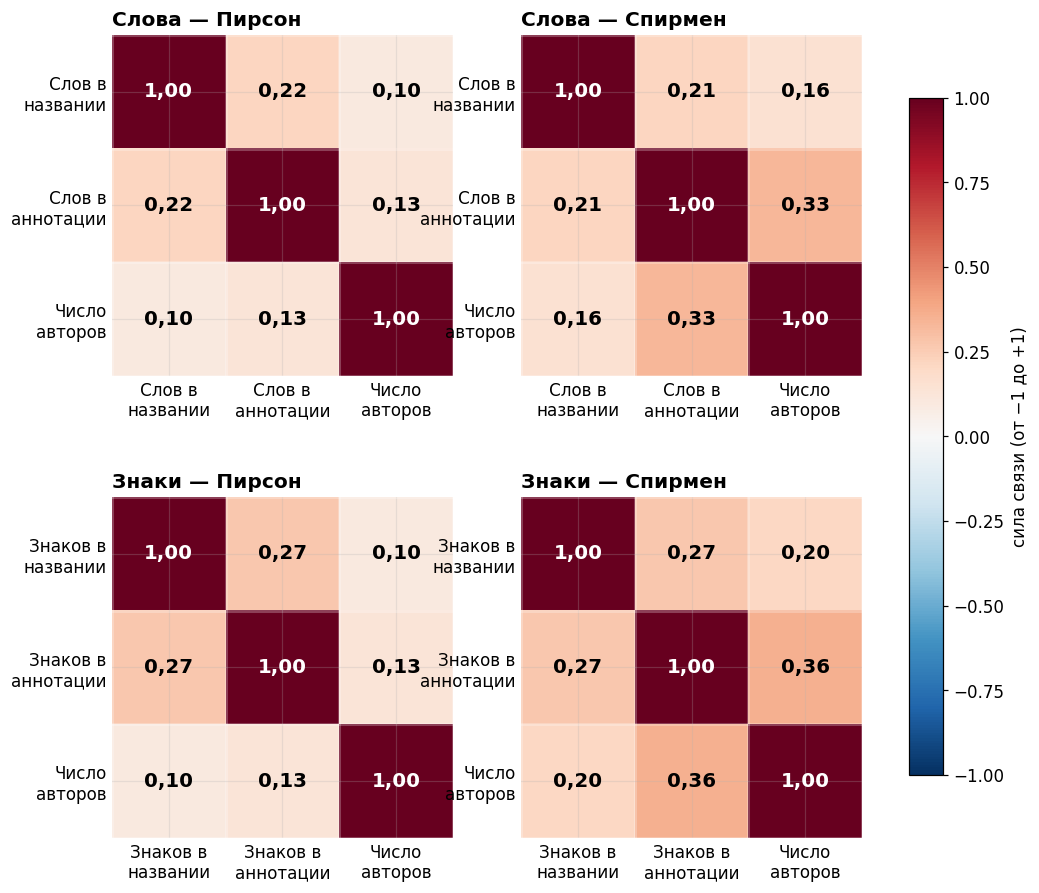

**Как читать.** 0 — связи нет; около +1 — чем больше одно, тем больше другое; около −1 — чем больше одно, тем меньше другое. **Пирсон** ищет прямую зависимость и чувствителен к редким огромным значениям (например, коллаборации в 255 авторов). **Спирмен** сравнивает только порядок («длиннее / короче») и поэтому устойчив к таким выбросам — если карты заметно различаются, виноваты именно выбросы.

In [11]:
# =============================================================================
# Связи между длиной названия, длиной аннотации и числом авторов (тепловые карты)
# Отдельно для слов и отдельно для знаков.
# Запуск в отдельной ячейке ноутбука:  exec(open('plot_corr.py').read())
# =============================================================================
import os
from pathlib import Path

import numpy as np
import polars as pl

# Какие данные берём: если есть очищенная копия (clean_dataset.py) - её, иначе исходные.
ROOT = Path(os.environ.get("ARXIV_ROOT", "data/optimized_v1"))
CLEAN = Path(os.environ.get("ARXIV_OUT", "data/optimized_v1_clean"))
if "ARXIV_ROOT" not in os.environ and (CLEAN / "meta").exists():
    ROOT = CLEAN
KEYS = ["id_prefix", "id_ym", "id_num"]


def parts(sub):
    return sorted((ROOT / sub).glob("part_*.parquet"))


def read(path, columns):
    return pl.read_parquet(path, columns=columns).with_columns(
        pl.col("id_prefix").cast(pl.String), pl.col("id_ym").cast(pl.Int64), pl.col("id_num").cast(pl.Int64))


# ---------- 1) по каждой статье: слова и знаки в названии и аннотации, число авторов ----------
authors = pl.concat([read(p, KEYS + ["n_authors"]) for p in parts("meta")])
chunks = []
for i, p in enumerate(parts("texts"), 1):
    d = read(p, KEYS + ["title", "abstract"])
    t, a = pl.col("title").cast(pl.String).fill_null(""), pl.col("abstract").cast(pl.String).fill_null("")
    d = d.select(*KEYS,
                 t.str.count_matches(r"\S+").alias("tw"), t.str.len_chars().alias("tc"),
                 a.str.count_matches(r"\S+").alias("aw"), a.str.len_chars().alias("ac"))
    chunks.append(d.join(authors, on=KEYS, how="inner").drop(KEYS))
    del d
    print(f"⏳ Читаю тексты, частей: {i}", end="\r")
df = pl.concat(chunks).drop_nulls()
del chunks, authors

# ---------- 2) корреляции ----------
GROUPS = {
    "Слова": (["tw", "aw", "n_authors"], ["Слов в\nназвании", "Слов в\nаннотации", "Число\nавторов"]),
    "Знаки": (["tc", "ac", "n_authors"], ["Знаков в\nназвании", "Знаков в\nаннотации", "Число\nавторов"]),
}
corr = {}
for group, (cols, labels) in GROUPS.items():
    x = df.select(cols).cast(pl.Float64)
    corr[(group, "Пирсон")] = (labels, np.corrcoef(x.to_numpy(), rowvar=False))
    ranks = x.select([pl.col(c).rank("average") for c in cols])  # для Спирмена: корреляция рангов
    corr[(group, "Спирмен")] = (labels, np.corrcoef(ranks.to_numpy(), rowvar=False))
n_rows = df.height
del df

# =============================================================================
# РИСОВАНИЕ
# =============================================================================
# --- РИСОВАНИЕ ---
import io

import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, clear_output, display

clear_output(wait=True)
plt.rcParams.update({"font.size": 11})
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for r, group in enumerate(GROUPS):
    for c, kind in enumerate(["Пирсон", "Спирмен"]):
        ax = axes[r, c]
        labels, m = corr[(group, kind)]
        im = ax.imshow(m, cmap="RdBu_r", vmin=-1, vmax=1)
        ax.set_xticks(range(len(labels)), labels)
        ax.set_yticks(range(len(labels)), labels)
        for i in range(len(labels)):
            for j in range(len(labels)):
                v = m[i, j]
                ax.text(j, i, f"{v:.2f}".replace(".", ","), ha="center", va="center",
                        fontsize=13, fontweight="bold", color="white" if abs(v) > .55 else "black")
        ax.set_title(f"{group} — {kind}", loc="left", fontweight="bold")
        ax.set_xticks(np.arange(-.5, len(labels)), minor=True)
        ax.set_yticks(np.arange(-.5, len(labels)), minor=True)
        ax.grid(which="minor", color="white", lw=2)
        ax.tick_params(which="both", length=0)
        for s in ax.spines.values():
            s.set_visible(False)
fig.colorbar(im, ax=axes, shrink=.8, label="сила связи (от −1 до +1)")
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
plt.close(fig)

display(Markdown(f"## Связи между длиной названия, аннотации и числом авторов\n"
                 f"Данные: `{ROOT}`, статей: **{n_rows:,}**.".replace(",", " ")))
display(Image(data=buf.getvalue()))
display(Markdown(
    "**Как читать.** 0 — связи нет; около +1 — чем больше одно, тем больше другое; около −1 — чем больше одно, "
    "тем меньше другое. **Пирсон** ищет прямую зависимость и чувствителен к редким огромным значениям "
    "(например, коллаборации в 255 авторов). **Спирмен** сравнивает только порядок («длиннее / короче») и "
    "поэтому устойчив к таким выбросам — если карты заметно различаются, виноваты именно выбросы."))

## Связи по годам
Данные: `data\optimized_v1_clean`  статей: **3 133 854**.

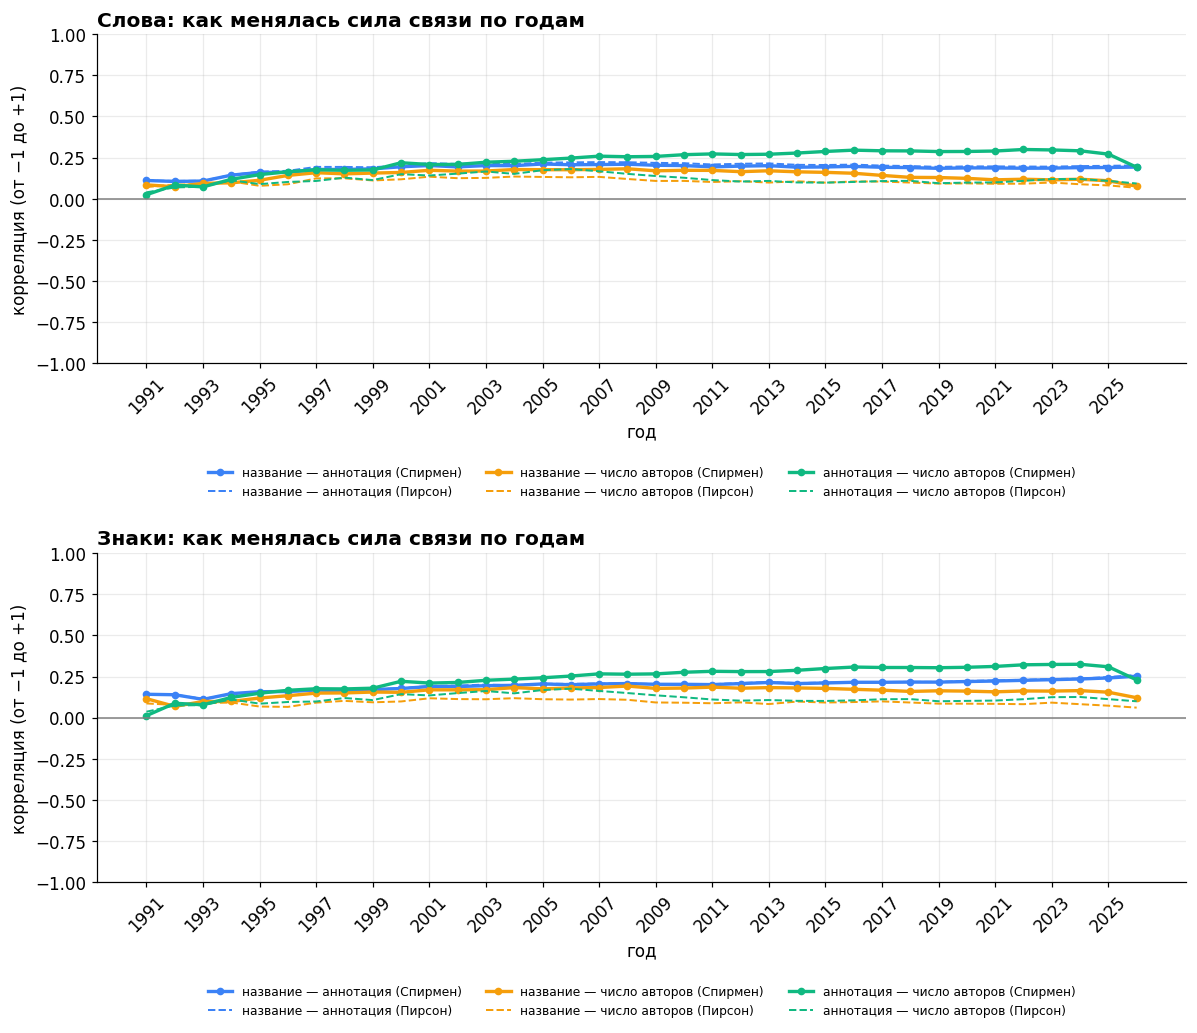

**Как читать.** Каждая линия - сила связи между двумя величинами в статьях конкретного года: выше нуля - чем больше одно, тем больше другое; ниже - наоборот. Сплошная линия (Спирмен) сравнивает только порядок и устойчива к выбросам, пунктир (Пирсон) чувствителен к редким огромным значениям.

## 3D: название × аннотация × число авторов
Случайные 20 000 статей; цвет - год. Оси обрезаны по 99,5-му процентилю, чтобы единичные гиганты не растягивали картину. Вместе длина названия и аннотации объясняют порядок числа авторов на **11,8 %** (чем ближе к 100 %, тем точнее по двум длинам можно угадать число авторов).

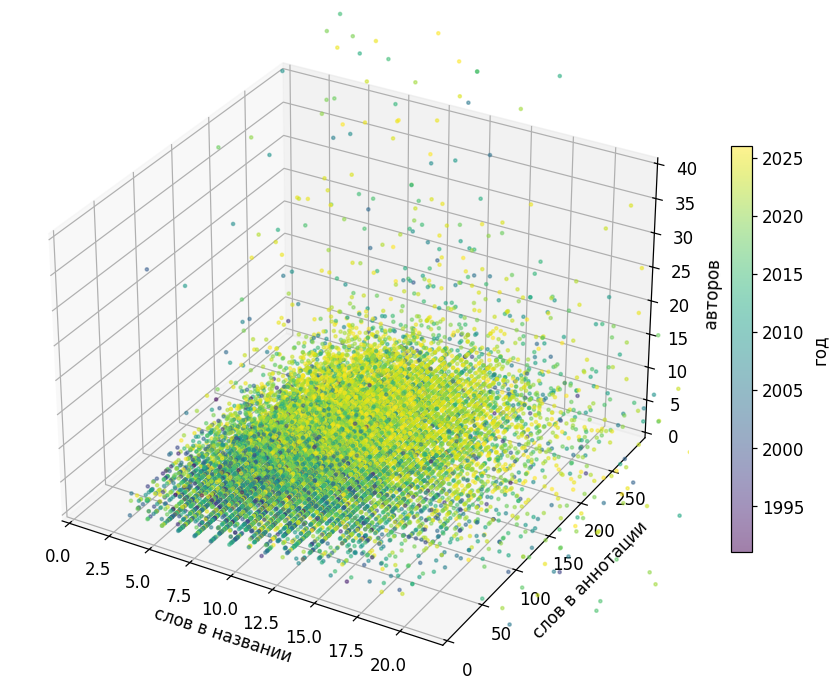

_Чтобы вращать график мышью, установите plotly: `pip install plotly` и перезапустите ячейку._

In [12]:
# =============================================================================
# 1) Как менялись связи между длиной названия, аннотации и числом авторов по годам
# 2) 3D-график: название × аннотация × число авторов (каждая точка - одна статья)
# Запуск в отдельной ячейке ноутбука:  exec(open('plot_corr_years.py').read())
# =============================================================================
import os
from pathlib import Path

import numpy as np
import polars as pl

ROOT = Path(os.environ.get("ARXIV_ROOT", "data/optimized_v1"))
CLEAN = Path(os.environ.get("ARXIV_OUT", "data/optimized_v1_clean"))
if "ARXIV_ROOT" not in os.environ and (CLEAN / "meta").exists():
    ROOT = CLEAN  # очищенная копия, если она есть
KEYS = ["id_prefix", "id_ym", "id_num"]
N_POINTS = 20000    # сколько статей показать точками на 3D-графике (случайная выборка)
MIN_PER_YEAR = 50   # в годах, где статей меньше, корреляцию не считаем


def parts(sub):
    return sorted((ROOT / sub).glob("part_*.parquet"))


def read(path, columns):
    return pl.read_parquet(path, columns=columns).with_columns(
        pl.col("id_prefix").cast(pl.String), pl.col("id_ym").cast(pl.Int64), pl.col("id_num").cast(pl.Int64))


# ---------- 1) по каждой статье: год, слова и знаки в названии и аннотации, число авторов ----------
authors = pl.concat([read(p, KEYS + ["n_authors"]) for p in parts("meta")])
yy = pl.col("id_ym") // 100
chunks = []
for i, p in enumerate(parts("texts"), 1):
    d = read(p, KEYS + ["title", "abstract"])
    t, a = pl.col("title").cast(pl.String).fill_null(""), pl.col("abstract").cast(pl.String).fill_null("")
    d = d.select(*KEYS, pl.when(yy >= 91).then(1900 + yy).otherwise(2000 + yy).alias("year"),
                 t.str.count_matches(r"\S+").alias("tw"), t.str.len_chars().alias("tc"),
                 a.str.count_matches(r"\S+").alias("aw"), a.str.len_chars().alias("ac"))
    chunks.append(d.join(authors, on=KEYS, how="inner").drop(KEYS))
    del d
    print(f"⏳ Читаю тексты, частей: {i}", end="\r")
df = pl.concat(chunks).drop_nulls()
del chunks, authors
n_rows = df.height

# ---------- 2) корреляции по годам ----------
GROUPS = {"Слова": ("tw", "aw"), "Знаки": ("tc", "ac")}
PAIRS = [("название — аннотация", 0, 1), ("название — число авторов", 0, 2), ("аннотация — число авторов", 1, 2)]
years = sorted(df["year"].unique().to_list())
yearly = {}  # (группа, вид) -> массив [годы x пары]
for group, (tcol, acol) in GROUPS.items():
    cols = [tcol, acol, "n_authors"]
    res = {"Пирсон": np.full((len(years), 3), np.nan), "Спирмен": np.full((len(years), 3), np.nan)}
    for k, y in enumerate(years):
        x = df.filter(pl.col("year") == y).select(cols).cast(pl.Float64)
        if x.height < MIN_PER_YEAR:
            continue
        for kind, m in (("Пирсон", x), ("Спирмен", x.select([pl.col(c).rank("average") for c in cols]))):
            a = m.to_numpy()
            if (a.std(axis=0) == 0).any():  # столбец без разброса: корреляция не определена
                continue
            c = np.corrcoef(a, rowvar=False)
            res[kind][k] = [c[i, j] for _, i, j in PAIRS]
    yearly.update({(group, kind): v for kind, v in res.items()})

# ---------- 3) совокупная связь трёх величин ----------
# Насколько длина названия и аннотации вместе объясняют число авторов (по рангам, чтобы выбросы не мешали)
rk = df.select([pl.col(c).rank("average") for c in ["tw", "aw", "n_authors"]]).to_numpy()
X = np.column_stack([rk[:, :2], np.ones(len(rk))])
beta, *_ = np.linalg.lstsq(X, rk[:, 2], rcond=None)
r2 = 1 - ((rk[:, 2] - X @ beta) ** 2).sum() / ((rk[:, 2] - rk[:, 2].mean()) ** 2).sum()
del rk, X

# ---------- 4) выборка для 3D ----------
smp = df.sample(min(N_POINTS, df.height), seed=0).select("year", "tw", "aw", "n_authors")
sx, sy, sz, sc = (smp[c].to_numpy() for c in ["tw", "aw", "n_authors", "year"])
del df

# =============================================================================
# РИСОВАНИЕ
# =============================================================================
# --- РИСОВАНИЕ ---
import io

import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, clear_output, display

clear_output(wait=True)
display(Markdown(f"## Связи по годам\nДанные: `{ROOT}`, статей: **{n_rows:,}**.".replace(",", " ")))

COLORS = ["#3b82f6", "#f59e0b", "#10b981"]
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})
fig, axes = plt.subplots(len(GROUPS), 1, figsize=(11, 4.8 * len(GROUPS)))
for ax, group in zip(np.atleast_1d(axes), GROUPS):
    for (name, _, _), color, j in zip(PAIRS, COLORS, range(3)):
        ax.plot(years, yearly[(group, "Спирмен")][:, j], color=color, lw=2.2, marker="o", ms=4, label=f"{name} (Спирмен)")
        ax.plot(years, yearly[(group, "Пирсон")][:, j], color=color, lw=1.3, ls="--", label=f"{name} (Пирсон)")
    ax.axhline(0, color="gray", lw=1)
    ax.set_ylim(-1, 1)
    ax.set_title(f"{group}: как менялась сила связи по годам", loc="left", fontweight="bold")
    ax.set_ylabel("корреляция (от −1 до +1)")
    ax.set_xlabel("год")
    ax.set_xticks(years[::2])
    plt.setp(ax.get_xticklabels(), rotation=45)
    ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.28))
fig.tight_layout()
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
plt.close(fig)
display(Image(data=buf.getvalue()))
display(Markdown(
    "**Как читать.** Каждая линия - сила связи между двумя величинами в статьях конкретного года: выше нуля - "
    "чем больше одно, тем больше другое; ниже - наоборот. Сплошная линия (Спирмен) сравнивает только порядок "
    "и устойчива к выбросам, пунктир (Пирсон) чувствителен к редким огромным значениям."))

# ---------- 3D ----------
cap = lambda a: float(np.percentile(a, 99.5))  # обрезаем осевые выбросы, чтобы облако не сжималось в точку
r2_txt = f"{100 * r2:.1f}".replace(".", ",")
n_txt = f"{len(sx):,}".replace(",", "\u00a0")
display(Markdown(
    f"## 3D: название × аннотация × число авторов\nСлучайные {n_txt} статей; цвет - год. "
    "Оси обрезаны по 99,5-му процентилю, чтобы единичные гиганты не растягивали картину. "
    f"Вместе длина названия и аннотации объясняют порядок числа авторов на **{r2_txt} %** "
    "(чем ближе к 100 %, тем точнее по двум длинам можно угадать число авторов)."))

try:
    import plotly.graph_objects as go
    fig3 = go.Figure(go.Scatter3d(
        x=sx, y=sy, z=sz, mode="markers",
        marker=dict(size=2.5, color=sc, colorscale="Viridis", opacity=.6, colorbar=dict(title="год")),
        hovertemplate="слов в названии: %{x}<br>слов в аннотации: %{y}<br>авторов: %{z}<br>год: %{marker.color}<extra></extra>"))
    fig3.update_layout(
        height=700, margin=dict(l=0, r=0, t=10, b=0),
        scene=dict(xaxis=dict(title="слов в названии", range=[0, cap(sx)]),
                   yaxis=dict(title="слов в аннотации", range=[0, cap(sy)]),
                   zaxis=dict(title="авторов", range=[0, cap(sz)])))
    fig3.show()  # график можно вращать мышью
except ImportError:
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(projection="3d")
    p = ax.scatter(sx, sy, sz, c=sc, cmap="viridis", s=4, alpha=.5)
    ax.set_xlim(0, cap(sx)); ax.set_ylim(0, cap(sy)); ax.set_zlim(0, cap(sz))
    ax.set_xlabel("слов в названии"); ax.set_ylabel("слов в аннотации"); ax.set_zlabel("авторов")
    fig.colorbar(p, ax=ax, shrink=.6, label="год")
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buf.getvalue()))
    display(Markdown("_Чтобы вращать график мышью, установите plotly: `pip install plotly` и перезапустите ячейку._"))

# Формулы и «шлак» в текстах по годам
Данные: `data\optimized_v1_clean`, статей: **3 133 648**. Доля - это процент статей данного года, где признак встретился хотя бы раз.

## 1. Формулы (LaTeX)

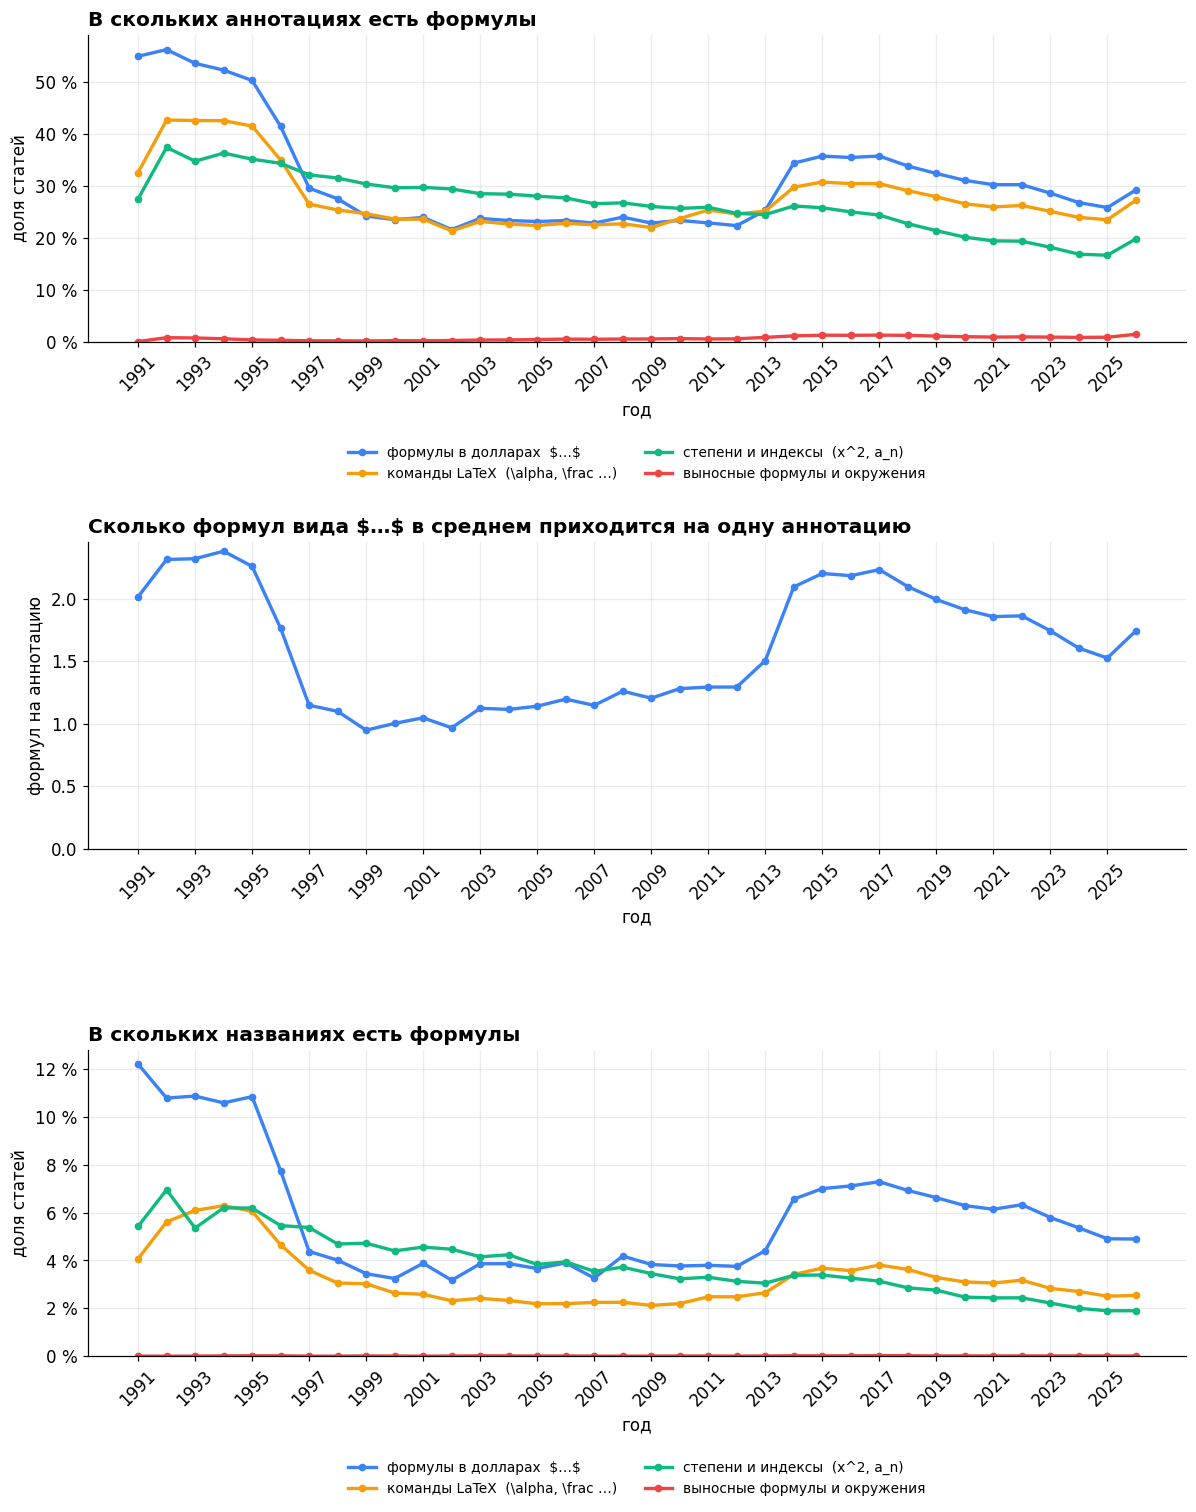

## 2. «Шлак»: HTML, кракозябры, невидимые знаки

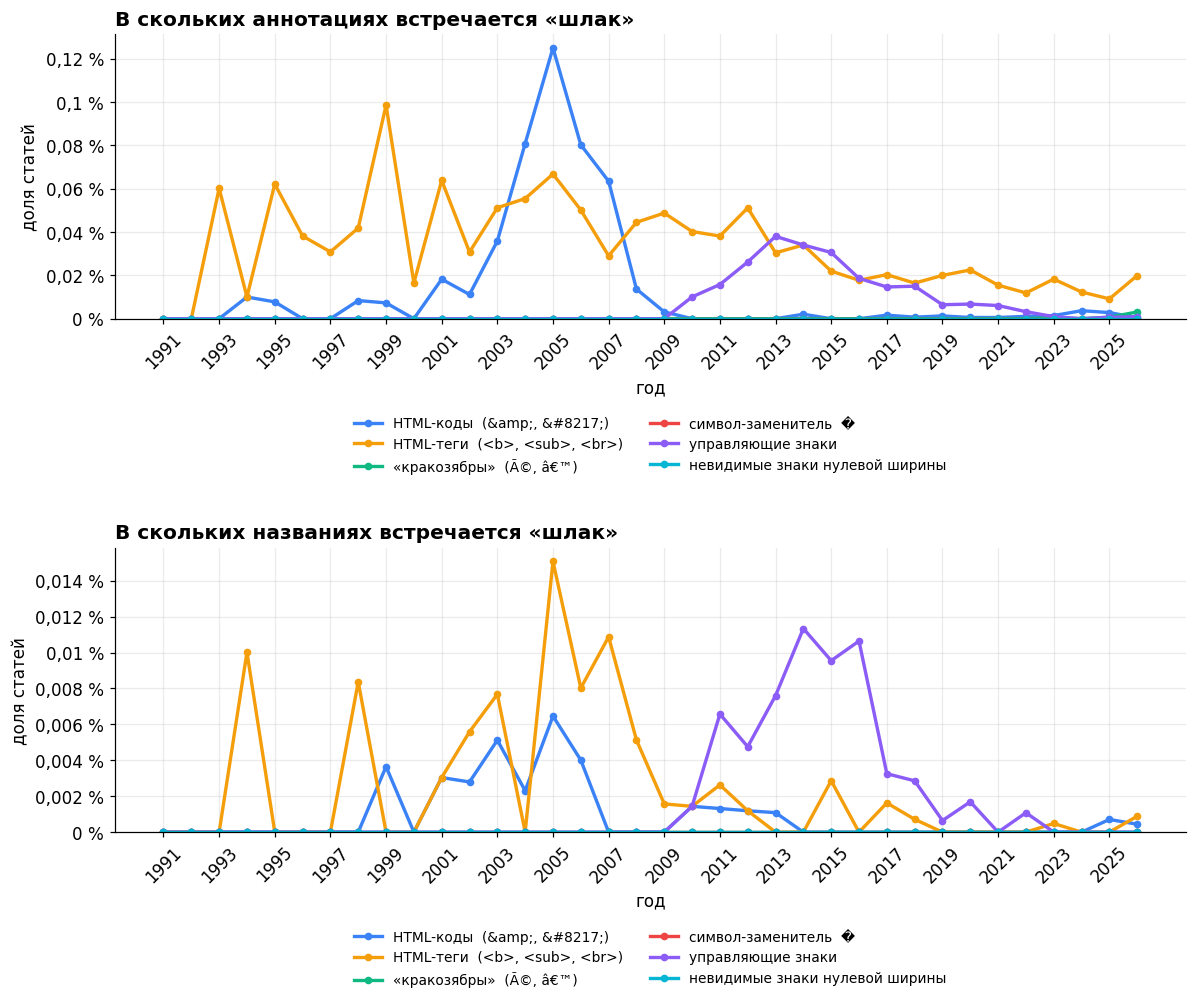

### Сколько всего статей затронуто
| Вид | В аннотациях | В названиях |
|---|---:|---:|
| HTML-коды  (&amp;  &#8217;) | 240 | 18 |
| HTML-теги  (<b>  <sub>  <br>) | 784 | 43 |
| «кракозябры»  (Ã©  â€™) | 10 | 0 |
| символ-заменитель  � | 0 | 0 |
| управляющие знаки | 246 | 64 |
| невидимые знаки нулевой ширины | 0 | 0 |

### Примеры для проверки
Сначала статьи с DOI. Невидимые знаки показаны как ⟦U+XXXX⟧.

Вид,Номер,Фрагмент аннотации,Ссылки
"HTML-коды (&amp;, &#8217;)",new/07041915,"of a sample of NEAs in the km-size range is 200 $\pm$ 40 J m&#8722;2 s&#8722;0.5 K&#8722;1. Furthermore, we identify a trend of",arXiv · DOI
"HTML-коды (&amp;, &#8217;)",new/07042026,the triboelectrification between two smooth monocrystalline &#945;-Al 2O 3 (sapphire) antagonists by surface force measurement,arXiv · DOI
"HTML-коды (&amp;, &#8217;)",new/07043808,"al model can generate a scale-free degree distribution, p(k)&prop; 1/k^&gamma;, with exponent &gamma;=1 in the non-growing cas",arXiv · DOI
"HTML-коды (&amp;, &#8217;)",new/07053384,which the nonlinear interaction occurred. Energies up to 5 &#956;J (1 kW peak power) have been achieved while keeping the ove,arXiv · DOI
"HTML-коды (&amp;, &#8217;)",new/07073616,"s(w)/dT (Eps : dielectric susceptibility, T : temperature, w&#61472;: frequency). To allow for an accurate determination of the",arXiv · DOI
"HTML-теги (<b>, <sub>, <br>)",new/07042175,"previously overestimated. It is found to be proportional to <I> instead of <I>^1.5, where <I> is the local average brightne",arXiv · DOI
"HTML-теги (<b>, <sub>, <br>)",new/0705507,se that D has a defining function r such that {z\in C^n:r(z)<a} is pseudoconvex for sufficiently small a>0. We also show that this condition is invariant under prope,arXiv · DOI
"HTML-теги (<b>, <sub>, <br>)",new/07061891,"hat, at a fixed value of the volume averaged magnetic field <B>, the amplitude of the low energy cut-off is mainly controle",arXiv · DOI
"HTML-теги (<b>, <sub>, <br>)",new/07072147,"the adjoint semigroup with respect to both scalar products $<a,b> = \tr(\rho a^* b)$ and $<a,b> = \tr(\rho^{1/2} a^* \rho^{1/",arXiv · DOI
"HTML-теги (<b>, <sub>, <br>)",new/07072371,ical Cepheids in I~Zw~18. The time-averaged Cepheid <V> and <I> magnitudes are compared to the VI reddening-free Wesenheit,arXiv · DOI


In [13]:
# =============================================================================
# Тренды по годам: формулы (LaTeX) в аннотациях и названиях, а также «шлак» в текстах:
# HTML-коды и теги, «кракозябры», символ-заменитель, управляющие и невидимые знаки.
# В конце - примеры статей со ссылками для проверки.
# Запуск в отдельной ячейке ноутбука:  exec(open('plot_markup.py').read())
# =============================================================================
import os
from pathlib import Path

import numpy as np
import polars as pl

ROOT = Path(os.environ.get("ARXIV_ROOT", "data/optimized_v1"))
CLEAN = Path(os.environ.get("ARXIV_OUT", "data/optimized_v1_clean"))
if "ARXIV_ROOT" not in os.environ and (CLEAN / "meta").exists():
    ROOT = CLEAN  # очищенная копия, если она есть
KEYS = ["id_prefix", "id_ym", "id_num"]
N_EXAMPLES = 5  # примеров на каждый вид «шлака»

FIELDS = {"abstract": "Аннотации", "title": "Названия"}

# Что считаем формулами: название вида -> (регулярное выражение, подпись на графике)
LATEX = {
    "math":    (r"(?s)\$[^$]+\$", "формулы в долларах  \\$…\\$"),
    "cmd":     (r"\\[a-zA-Z]{2,}", "команды LaTeX  (\\alpha, \\frac …)"),
    "supsub":  (r"[_^]\{|[A-Za-z0-9)}][_^][A-Za-z0-9{]", "степени и индексы  (x^2, a_n)"),
    "display": (r"\$\$|\\\[|\\begin\{", "выносные формулы и окружения"),
}
MATH_COUNT = r"(?s)\$[^$]+\$"  # для «в среднем формул на текст»

# Что считаем «шлаком»
JUNK = {
    "entity":  (r"&(?:#[0-9]{1,6}|#[xX][0-9a-fA-F]{1,5}|[a-zA-Z][a-zA-Z0-9]{1,8});", "HTML-коды  (&amp;, &#8217;)"),
    "tag":     (r"(?i)</?(?:b|i|em|strong|sub|sup|br|p|a|span|div|u|tt|code|font|ul|ol|li|table|tr|td|h[1-6]|math|mi|mo|mn|img)\b[^<>]*>",
                "HTML-теги  (<b>, <sub>, <br>)"),
    "mojibake": (r"Ã[\x{80}-\x{BF}]|â€|Â[\x{A0}-\x{BF}]", "«кракозябры»  (Ã©, â€™)"),
    "replace": (r"\x{FFFD}", "символ-заменитель  �"),
    "control": (r"[\x00-\x08\x0B\x0C\x0E-\x1F\x7F]", "управляющие знаки"),
    "invisible": (r"[\x{200B}-\x{200D}\x{2060}\x{FEFF}]", "невидимые знаки нулевой ширины"),
}
ALL = {**LATEX, **JUNK}


def parts(sub):
    return sorted((ROOT / sub).glob("part_*.parquet"))


def read(path, columns):
    have = set(pl.scan_parquet(path).collect_schema().names())
    return pl.read_parquet(path, columns=[c for c in columns if c in have]).with_columns(
        pl.col("id_prefix").cast(pl.String), pl.col("id_ym").cast(pl.Int64), pl.col("id_num").cast(pl.Int64))


def arxiv_id(prefix, ym, num):
    if prefix:
        return f"{prefix}/{int(ym):04d}{int(num):03d}"
    return f"{int(ym):04d}.{int(num):0{4 if int(ym) < 1501 else 5}d}"


yy = pl.col("id_ym") // 100
year = pl.when(yy >= 91).then(1900 + yy).otherwise(2000 + yy).alias("year")

# ---------- 1) считаем по частям: в скольких статьях каждого года встретился каждый признак ----------
agg_parts, ex_parts = [], []
for i, p in enumerate(parts("texts"), 1):
    d = read(p, KEYS + ["title", "abstract"]).with_columns(year)
    exprs = []
    for f in FIELDS:
        s = pl.col(f).cast(pl.String).fill_null("")
        for k, (rx, _) in ALL.items():
            exprs.append(s.str.contains(rx).cast(pl.Int64).alias(f"{f}|{k}"))
        exprs.append(s.str.count_matches(MATH_COUNT).alias(f"{f}|nmath"))
    agg_parts.append(d.select("year", *exprs).group_by("year").agg(pl.len().alias("n"), pl.exclude("year").sum()))
    # примеры «шлака» (только аннотации): кусочек текста вокруг находки
    s = pl.col("abstract").cast(pl.String).fill_null("")
    for k, (rx, _) in JUNK.items():
        hit = d.filter(s.str.contains(rx)).head(40)
        if hit.height:
            ex_parts.append(hit.select(*KEYS, pl.lit(k).alias("kind"),
                                       pl.col("abstract").cast(pl.String).str.extract(r"(?s).{0,60}(?:" + rx + r").{0,60}", 0).alias("snippet")))
    del d
    print(f"⏳ Просмотрено частей: {i}", end="\r")

tab = pl.concat(agg_parts).group_by("year").agg(pl.all().sum()).sort("year")
years = tab["year"].to_list()
N = tab["n"].to_numpy().astype(float)
S = {(f, k): 100 * tab[f"{f}|{k}"].to_numpy() / N for f in FIELDS for k in ALL}        # доля статей, %
M = {f: tab[f"{f}|nmath"].to_numpy() / N for f in FIELDS}                               # формул на текст
total_n = int(N.sum())

# ---------- 2) примеры «шлака» со ссылками ----------
ex = pl.concat(ex_parts) if ex_parts else None
examples = []
if ex is not None:
    meta = pl.concat([read(p, KEYS + ["doi"]).join(ex.select(KEYS).unique(), on=KEYS, how="semi") for p in parts("meta")],
                     how="diagonal_relaxed")
    ex = ex.join(meta, on=KEYS, how="left") if "doi" in meta.columns else ex.with_columns(pl.lit(None).alias("doi"))
    ex = ex.with_columns((pl.col("doi").is_not_null() & (pl.col("doi").cast(pl.String).str.strip_chars() != "")).alias("has_doi"))
    for k in JUNK:
        sub = ex.filter(pl.col("kind") == k).sort("has_doi", descending=True).head(N_EXAMPLES)
        for r in sub.iter_rows(named=True):
            examples.append(dict(kind=k, id=arxiv_id(r["id_prefix"], r["id_ym"], r["id_num"]),
                                 snippet=r["snippet"] or "", doi=(r.get("doi") or "")))

# =============================================================================
# РИСОВАНИЕ
# =============================================================================
# --- РИСОВАНИЕ ---
import html
import io
import unicodedata

import matplotlib.pyplot as plt
from IPython.display import HTML, Image, Markdown, clear_output, display

clear_output(wait=True)
COLORS = ["#3b82f6", "#f59e0b", "#10b981", "#ef4444", "#8b5cf6", "#06b6d4"]
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})
pct_fmt = plt.FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",") + " %")


def show(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buf.getvalue()))


def lines(ax, field, kinds, title):
    for (k, (_, label)), color in zip(kinds.items(), COLORS):
        ax.plot(years, S[(field, k)], color=color, lw=2.2, marker="o", ms=4, label=label)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_ylabel("доля статей")
    ax.set_xlabel("год")
    ax.set_xticks(years[::2])
    plt.setp(ax.get_xticklabels(), rotation=45)
    ax.yaxis.set_major_formatter(pct_fmt)
    ax.set_ylim(bottom=0)
    ax.legend(frameon=False, fontsize=9, ncol=2, loc="upper center", bbox_to_anchor=(.5, -.3))


n_txt = f"{total_n:,}".replace(",", " ")
display(Markdown(f"# Формулы и «шлак» в текстах по годам\nДанные: `{ROOT}`, статей: **{n_txt}**. "
                 "Доля - это процент статей данного года, где признак встретился хотя бы раз."))

# --- LaTeX ---
display(Markdown("## 1. Формулы (LaTeX)"))
fig, axes = plt.subplots(3, 1, figsize=(11, 14))
lines(axes[0], "abstract", LATEX, "В скольких аннотациях есть формулы")
axes[1].plot(years, M["abstract"], color="#3b82f6", lw=2.2, marker="o", ms=4)
axes[1].set_title("Сколько формул вида \\$…\\$ в среднем приходится на одну аннотацию", loc="left", fontweight="bold")
axes[1].set_ylabel("формул на аннотацию"); axes[1].set_xlabel("год")
axes[1].set_xticks(years[::2]); plt.setp(axes[1].get_xticklabels(), rotation=45); axes[1].set_ylim(bottom=0)
lines(axes[2], "title", LATEX, "В скольких названиях есть формулы")
fig.tight_layout()
show(fig)

# --- шлак ---
display(Markdown("## 2. «Шлак»: HTML, кракозябры, невидимые знаки"))
fig, axes = plt.subplots(2, 1, figsize=(11, 9.5))
lines(axes[0], "abstract", JUNK, "В скольких аннотациях встречается «шлак»")
lines(axes[1], "title", JUNK, "В скольких названиях встречается «шлак»")
fig.tight_layout()
show(fig)

# --- итоги по «шлаку» ---
rows = []
for k, (_, label) in JUNK.items():
    ca = int(round(sum(S[("abstract", k)] * N) / 100))
    ct = int(round(sum(S[("title", k)] * N) / 100))
    rows.append(f"| {label} | {ca:,} | {ct:,} |".replace(",", " "))
display(Markdown("### Сколько всего статей затронуто\n| Вид | В аннотациях | В названиях |\n|---|---:|---:|\n" + "\n".join(rows)))

# --- примеры ---
if examples:
    def visible(s):
        """Показываем невидимые и управляющие знаки как ⟦U+XXXX⟧, чтобы их было видно."""
        return "".join(f"⟦U+{ord(c):04X}⟧" if unicodedata.category(c) in ("Cc", "Cf") and c not in "\n\t" else c for c in s)

    TH = "text-align:left;padding:6px 10px;background:rgba(128,128,128,.18);border-bottom:2px solid rgba(128,128,128,.4);"
    TD = "padding:6px 10px;border-bottom:1px solid rgba(128,128,128,.25);vertical-align:top;"
    out = ['<table style="border-collapse:collapse;font-size:13px;width:100%;"><thead><tr>'
           + "".join(f'<th style="{TH}">{h}</th>' for h in ["Вид", "Номер", "Фрагмент аннотации", "Ссылки"]) + "</tr></thead><tbody>"]
    for r in examples:
        links = f'<a href="https://arxiv.org/abs/{html.escape(r["id"])}" target="_blank">arXiv</a>'
        links += (f' · <a href="https://doi.org/{html.escape(r["doi"])}" target="_blank">DOI</a>' if r["doi"]
                  else ' · <span style="opacity:.5">нет DOI</span>')
        cells = [html.escape(JUNK[r["kind"]][1]), f"<b>{html.escape(r['id'])}</b>",
                 f'<span style="font-family:monospace">{html.escape(visible(" ".join(r["snippet"].split())))}</span>', links]
        out.append("<tr>" + "".join(f'<td style="{TD}">{c}</td>' for c in cells) + "</tr>")
    out.append("</tbody></table>")
    display(Markdown("### Примеры для проверки\nСначала статьи с DOI. Невидимые знаки показаны как ⟦U+XXXX⟧."))
    display(HTML("".join(out)))